# Quanteninformationstheorie und Abstandsmaße

Das Notebook stellt die Abstandsmaße zwischen Quantenzuständen und -kanälen (Spurabstand, Fidelity, Bures, Hilbert-Schmidt, relative Entropie, Chernoff-Exponent, Diamantnorm) und die Entropien (von Neumann, Rényi, bedingte und gegenseitige Information) mit ihren Ungleichungen zusammen. Jede Aussage wird mit numpy an Zufallszuständen geprüft (SDPs mit cvxpy), und ihre operative Bedeutung wird simuliert: Unterscheiden mit vielen Kopien, Schumacher-Kompression, Holevo-Schranke und Accessible Information, Kanalkapazitäten, No-Cloning mit optimalem Klonen, Quanten-Fisher-Information.

Wie misst man, wie verschieden zwei Quantenzustände oder zwei Kanäle sind und wie viel Information ein Zustand trägt, und welche Grenzen folgen daraus für das, was man mit Quantenzuständen tun kann?

#### **Hintergrund**

Ein Abstandsmaß ist nur so gut wie die Aufgabe, die es beschreibt. Der Spurabstand sagt, wie gut man zwei Zustände mit einer Messung unterscheiden kann; die Fidelity, wie stark sich ihre Purifikationen überlappen; die relative Entropie, wie schnell der Fehler mit der Zahl der Kopien fällt. Entropien zählen Ressourcen: Qubits für die Kompression, Bits, die man auslesen kann, Kapazitäten von Kanälen. Die Messungen, mit denen man diese Grenzen erreicht (Helstrom, POVMs, Tomographie), stehen im Notebook [Quantenmessung](https://github.com/deltorobarba/science/blob/main/quantum/quantummeasurement.ipynb).

Landkarte:

| Familie | Größe | Formel | Bedeutung | Hier |
| --- | --- | --- | --- | --- |
| Abstände zwischen Zuständen | Spurabstand | $T = \tfrac12\Vert\rho - \sigma\Vert_1$ | beste Unterscheidung mit einer Kopie (Helstrom) | Exp. 1–4 |
| | Fidelity | $F = \big(\mathrm{Tr}\sqrt{\sqrt\rho\,\sigma\sqrt\rho}\big)^2$ | Überlapp der besten Purifikationen (Uhlmann) | Exp. 1–3 |
| | Bures-Abstand, Bures-Winkel | $\sqrt{2(1 - \sqrt F)}$, $\arccos\sqrt F$ | Riemannsche Metrik auf den Zuständen | Exp. 1, 9 |
| | Hilbert-Schmidt-Abstand | $\Vert\rho - \sigma\Vert_2$ | leicht zu rechnen, aber nicht kontraktiv | Exp. 1, 3 |
| | Relative Entropie | $D(\rho\Vert\sigma) = \mathrm{Tr}\,\rho(\log\rho - \log\sigma)$ | Fehlerexponent beim asymmetrischen Testen (Stein) | Exp. 2–4 |
| | Quanten-Chernoff-Exponent | $\xi = -\log\min_s\mathrm{Tr}\,\rho^s\sigma^{1-s}$ | Fehlerexponent beim Unterscheiden mit $n$ Kopien | Exp. 4 |
| Entropien | von Neumann | $S(\rho) = -\mathrm{Tr}\,\rho\log\rho$ | Qubits pro Kopie bei der Kompression (Schumacher) | Exp. 5, 6 |
| | Rényi | $S_\alpha = \tfrac1{1-\alpha}\log\mathrm{Tr}\,\rho^\alpha$ | Reinheit ($\alpha = 2$), Min-Entropie ($\alpha\to\infty$) | Exp. 5 |
| | bedingte Entropie, gegenseitige Information | $S(A\vert B) = S(AB) - S(B)$, $I(A{:}B)$ | kann negativ sein: Zeichen von Verschränkung | Exp. 5 |
| | Ungleichungen | Subadditivität, Araki–Lieb, starke Subadditivität | Gerüst aller Entropie-Aussagen | Exp. 5 |
| Information | Holevo-Schranke | $I(X{:}Y)\le\chi\le\log d$ | ein Qubit trägt höchstens ein Bit | Exp. 7 |
| | Accessible Information | $\max_\text{POVM}I(X{:}Y)$ | was man wirklich auslesen kann | Exp. 7 |
| | Kanalkapazitäten | $C$, $Q$, $C_E$ | klassische, Quanten- und verschränkungsunterstützte Kapazität | Exp. 11 |
| No-Go-Sätze | No-Cloning, No-Broadcasting, No-Deleting, No-Signalling | Linearität, Unitarität, Partialspur | was verboten ist und wie nahe man herankommt | Exp. 8 |
| Geometrie | Quanten-Fisher-Information | $F_Q = 4\,(dD_B/d\theta)^2$ | beste Genauigkeit einer Parameterschätzung | Exp. 9 |
| Abstände zwischen Kanälen | Diamantnorm | $\tfrac12\Vert\mathcal E - \mathcal F\Vert_\diamond$ | beste Unterscheidung zweier Kanäle, mit Ancilla | Exp. 10 |
| | Prozess- und mittlere Gatter-Fidelity | $F_\text{avg} = (dF_\text{pro} + 1)/(d + 1)$ | das, was Randomized Benchmarking misst | Exp. 10 |

Nicht simuliert, aber Teil der Landkarte (Abschnitt „Nächste Schritte“): Min- und Max-Entropien für einzelne Durchläufe (One-Shot), gestauchte Rényi-Divergenzen, Verschränkungsmaße (Verschränkungsentropie, Negativität, Concurrence), Quantum Discord, private Kapazität und Superaktivierung.

#### **Theorie**

Logarithmen sind, wo nicht anders gesagt, zur Basis 2 (Einheit Bit). $h(x) = -x\log_2x - (1-x)\log_2(1-x)$ ist die binäre Entropie.

##### *1. Die klassische Vorlage*

Für zwei Wahrscheinlichkeitsverteilungen $p, q$:
- **Totalvariationsabstand** $\mathrm{TV}(p,q) = \tfrac12\sum_i\vert p_i - q_i\vert = \max_A\big(p(A) - q(A)\big)$, das Maximum über alle Ereignisse $A$.
- **Klassische Fidelity** (Bhattacharyya) $F(p,q) = \big(\sum_i\sqrt{p_iq_i}\big)^2$.
- **Kullback–Leibler-Divergenz** $D(p\Vert q) = \sum_ip_i\log(p_i/q_i)$ und **Shannon-Entropie** $H(p) = -\sum_ip_i\log p_i$.

Die Quantengrößen gehen in diese über, wenn $\rho$ und $\sigma$ vertauschen (in derselben Basis diagonal sind). Für jede Messung mit Ergebnisverteilungen $p$ (aus $\rho$) und $q$ (aus $\sigma$) gilt $\mathrm{TV}(p,q)\le T(\rho,\sigma)$, $F(p,q)\ge F(\rho,\sigma)$ und $D(p\Vert q)\le D(\rho\Vert\sigma)$; beim Spurabstand und bei der Fidelity wird die Grenze von einer passenden Messung erreicht.

##### *2. Abstände zwischen Zuständen*

- **Spurnorm** $\Vert A\Vert_1 = \mathrm{Tr}\sqrt{A^\dagger A}$, für hermitesche $A$ die Summe der Beträge der Eigenwerte. **Spurabstand** $T(\rho,\sigma) = \tfrac12\Vert\rho - \sigma\Vert_1\in[0,1]$, mit der Variationsform $T = \max_{0\le P\le I}\mathrm{Tr}\big(P(\rho - \sigma)\big)$. Für Qubits mit Bloch-Vektoren $\vec r, \vec s$: $T = \tfrac12\vert\vec r - \vec s\vert$.
- **Fidelity** $F(\rho,\sigma) = \big(\mathrm{Tr}\sqrt{\sqrt\rho\,\sigma\sqrt\rho}\big)^2 = \Vert\sqrt\rho\sqrt\sigma\Vert_1^2\in[0,1]$, symmetrisch. Reine Zustände: $F = \vert\langle\psi\vert\phi\rangle\vert^2$; ein reiner und ein gemischter: $F = \langle\psi\vert\sigma\vert\psi\rangle$; Qubits: $F = \mathrm{Tr}(\rho\sigma) + 2\sqrt{\det\rho\,\det\sigma}$. Achtung Konvention: Nielsen–Chuang nennen die Wurzel $\sqrt F$ „Fidelity“. **Satz von Uhlmann:** $F(\rho,\sigma) = \max\vert\langle\psi_\rho\vert\psi_\sigma\rangle\vert^2$ über alle Purifikationen.
- Aus der Fidelity abgeleitet: **Bures-Abstand** $D_B = \sqrt{2(1 - \sqrt F)}$ und **Bures-Winkel** $A = \arccos\sqrt F$; beide sind Metriken.
- **Hilbert-Schmidt-Abstand** $\Vert\rho - \sigma\Vert_2 = \sqrt{\mathrm{Tr}(\rho - \sigma)^2}$; es gilt $\Vert A\Vert_2\le\Vert A\Vert_1\le\sqrt{\mathrm{rang}\,A}\,\Vert A\Vert_2$.
- **Fuchs–van de Graaf:** $1 - \sqrt F\le T\le\sqrt{1 - F}$; für reine Zustände gilt rechts Gleichheit.
- **Datenverarbeitung:** Für jeden Kanal $\mathcal E$ (vollständig positiv, spurerhaltend) ist $T(\mathcal E(\rho),\mathcal E(\sigma))\le T(\rho,\sigma)$, $F(\mathcal E(\rho),\mathcal E(\sigma))\ge F(\rho,\sigma)$ und $D(\mathcal E(\rho)\Vert\mathcal E(\sigma))\le D(\rho\Vert\sigma)$: Verarbeitung macht Zustände nie unterscheidbarer. Für den Hilbert-Schmidt-Abstand gilt das **nicht**.

##### *3. Unterscheiden mit vielen Kopien*

- Eine Kopie, gleiche Priors: $P_\text{err} = \tfrac12(1 - T)$ (Helstrom).
- $n$ Kopien: $P_\text{err}^{(n)} = \tfrac12\big(1 - T(\rho^{\otimes n},\sigma^{\otimes n})\big)$ fällt exponentiell, $P_\text{err}^{(n)}\approx e^{-n\xi}$ mit dem **Quanten-Chernoff-Exponenten** $\xi = -\ln Q$, $Q = \min_{0\le s\le1}\mathrm{Tr}\,\rho^s\sigma^{1-s}$ (Audenaert et al. 2007, Nussbaum–Szkoła 2009). Für jedes $n$ gilt $\tfrac12\big(1 - \sqrt{1 - F^n}\big)\le P_\text{err}^{(n)}\le\tfrac12Q^n$.
- **Asymmetrisch (Quanten-Stein-Lemma):** Hält man die Fehlerwahrscheinlichkeit erster Art unter einer festen Schranke, fällt die zweiter Art wie $e^{-nD(\rho\Vert\sigma)}$ (natürlicher Logarithmus; Hiai–Petz 1991, Ogawa–Nagaoka 2000). Das ist die operative Bedeutung der relativen Entropie.
- **Pinsker:** $D(\rho\Vert\sigma)\ge\tfrac{2}{\ln2}T^2$ (in Bit).

##### *4. Entropien*

- **Von-Neumann-Entropie** $S(\rho) = -\mathrm{Tr}\,\rho\log\rho = H(\lambda)$, die Shannon-Entropie der Eigenwerte. $0\le S\le\log d$; $S = 0$ genau für reine Zustände, $S = \log d$ genau für $I/d$. Invariant unter Unitären, konkav.
- **Rényi-Entropien** $S_\alpha(\rho) = \tfrac1{1-\alpha}\log\mathrm{Tr}\,\rho^\alpha$, fallend in $\alpha$: $S_0 = \log\mathrm{rang}\,\rho$, $S_1 = S$, $S_2 = -\log\mathrm{Tr}\,\rho^2$ (Reinheit), $S_\infty = -\log\lambda_\text{max}$ (Min-Entropie).
- Für zwei Systeme: **bedingte Entropie** $S(A\vert B) = S(AB) - S(B)$, **gegenseitige Information** $I(A{:}B) = S(A) + S(B) - S(AB)$, für drei Systeme die **bedingte gegenseitige Information** $I(A{:}C\vert B) = S(AB) + S(BC) - S(ABC) - S(B)$.
- Klassisch ist $H(A\vert B)\ge0$. Quantenmechanisch kann $S(A\vert B)$ bis $-\log d$ fallen (Bell-Zustand: $-1$). Ist $S(A\vert B)<0$, ist der Zustand verschränkt; die Umkehrung gilt nicht. Operativ ist $-S(A\vert B)$ die Verschränkung, die beim State Merging übrig bleibt (Horodecki, Oppenheim, Winter 2005).
- **Relative Entropie** $D(\rho\Vert\sigma) = \mathrm{Tr}\,\rho(\log\rho - \log\sigma)\ge0$ (Ungleichung von Klein), gleich null nur für $\rho = \sigma$, unendlich, wenn der Träger von $\rho$ nicht im Träger von $\sigma$ liegt; nicht symmetrisch. $I(A{:}B) = D(\rho_{AB}\Vert\rho_A\otimes\rho_B)$.
- **Ungleichungen:**
  - Subadditivität $S(AB)\le S(A) + S(B)$, also $I(A{:}B)\ge0$;
  - Araki–Lieb $\vert S(A) - S(B)\vert\le S(AB)$;
  - **starke Subadditivität** (Lieb–Ruskai 1973) $S(ABC) + S(B)\le S(AB) + S(BC)$, gleichwertig mit $I(A{:}C\vert B)\ge0$ und mit der Monotonie der relativen Entropie unter der Partialspur;
  - $I(A{:}B)\le2\min\big(S(A), S(B)\big)$, klassisch nur $\le\min$;
  - Mischung: $\sum_ip_iS(\rho_i)\le S\big(\sum_ip_i\rho_i\big)\le\sum_ip_iS(\rho_i) + H(p)$.

##### *5. Information: Kompression, Holevo, Kapazitäten*

- **Schumacher-Kompression:** $n$ Kopien eines Zustands $\rho$ lassen sich für $n\to\infty$ mit Fidelity gegen 1 in $nS(\rho)$ Qubits speichern, in weniger nicht. Das ist die operative Bedeutung der von-Neumann-Entropie.
- **Holevo-Schranke:** Alice kodiert $x$ mit Wahrscheinlichkeit $p_x$ im Zustand $\rho_x$. Für jede Messung von Bob mit Ergebnis $Y$ gilt
$$I(X{:}Y)\le\chi = S\Big(\sum_xp_x\rho_x\Big) - \sum_xp_xS(\rho_x)\le\log d .$$
Das Maximum über alle Messungen heißt **Accessible Information** $I_\text{acc}$; oft ist $I_\text{acc}<\chi$. Folge: $n$ Qubits übertragen ohne vorher geteilte Verschränkung höchstens $n$ Bit. Superdense Coding (2 Bit pro gesendetem Qubit) widerspricht dem nicht, weil die vier Codezustände auf zwei Qubits leben.
- **Kapazitäten eines Kanals** $\mathcal E$, jeweils als Grenzwert über $n$ parallele Nutzungen:
  - klassisch (Holevo, Schumacher–Westmoreland): $C = \lim_n\tfrac1n\chi(\mathcal E^{\otimes n})$ mit $\chi(\mathcal E) = \max_{\{p_x,\rho_x\}}\chi(\{p_x,\mathcal E(\rho_x)\})$; für den depolarisierenden Kanal ist $\chi$ additiv (King 2003);
  - Quantenkapazität (Lloyd, Shor, Devetak): $Q = \lim_n\tfrac1n\max I_c(\mathcal E^{\otimes n})$ mit der **kohärenten Information** $I_c = S(B) - S(RB)$, wenn eine Hälfte $A$ eines reinen Zustands auf $RA$ durch den Kanal geht. $I_c$ einer einzelnen Nutzung ist eine untere Schranke (Hashing); für degradierbare Kanäle (Amplitudendämpfung mit $\gamma\le\tfrac12$) ist sie exakt, für antidegradierbare ist $Q = 0$;
  - verschränkungsunterstützt (Bennett, Shor, Smolin, Thapliyal): $C_E = \max_\rho I(R{:}B)$, ohne Grenzwert.

##### *6. No-Go-Sätze*

- **No-Cloning** (Wootters–Zurek, Dieks 1982): Keine Unitäre $U$ erfüllt $U\vert\psi\rangle\vert0\rangle = \vert\psi\rangle\vert\psi\rangle$ für alle $\vert\psi\rangle$. Die beste universelle symmetrische $1\to2$-Klonmaschine (Bužek–Hillery 1996) erreicht pro Kopie die Fidelity $5/6$; Messen und neu Präparieren erreicht im Mittel nur $2/3$.
- **No-Broadcasting** (Barnum et al. 1996): Eine Menge gemischter Zustände lässt sich nur dann verteilen (beide Empfänger erhalten den Zustand als reduzierten Zustand), wenn die Zustände vertauschen.
- **No-Deleting** (Pati–Braunstein 2000): Kein linearer Prozess löscht von zwei Kopien eines unbekannten Zustands eine, $\vert\psi\rangle\vert\psi\rangle\vert A\rangle\mapsto\vert\psi\rangle\vert0\rangle\vert A_\psi\rangle$, ohne dass die Kopie in der Umgebung $\vert A_\psi\rangle$ erhalten bleibt.
- **No-Signalling:** Keine lokale Operation von Alice ändert den reduzierten Zustand von Bob. Verschränkung allein überträgt also keine Information; Teleportation braucht zwei klassische Bits.
- Dazu gehört „keine Information ohne Störung“ (Notebook Quantenmessung, Experiment 2).

##### *7. Quanten-Fisher-Information*

Für eine Familie $\rho_\theta$ ist der Bures-Abstand benachbarter Zustände $D_B^2(\rho_\theta,\rho_{\theta+d\theta}) = \tfrac14F_Q(\theta)\,d\theta^2$; $F_Q$ heißt **Quanten-Fisher-Information**. Für reine Zustände $\vert\psi_\theta\rangle = e^{-i\theta G}\vert\psi\rangle$ ist $F_Q = 4\,\mathrm{Var}_\psi(G)$. **Quanten-Cramér–Rao-Schranke:** Jede erwartungstreue Schätzung aus $\nu$ Wiederholungen hat $\Delta\theta\ge1/\sqrt{\nu F_Q}$, und für große $\nu$ ist die Schranke erreichbar (Braunstein–Caves 1994). $N$ Qubits mit $G = \tfrac12\sum_i\sigma_z^{(i)}$: Produktzustand $\vert{+}\rangle^{\otimes N}$ gibt $F_Q = N$ (Standard-Quantenlimit $\Delta\theta\propto1/\sqrt N$), GHZ gibt $F_Q = N^2$ (Heisenberg-Limit $1/N$). Mit Dephasierung $p$ pro Qubit: $N(1 - 2p)^2$ gegen $N^2(1 - 2p)^{2N}$.

##### *8. Abstände zwischen Kanälen*

- **Diamantnorm:** $\tfrac12\Vert\mathcal E - \mathcal F\Vert_\diamond = \max_{\rho_{RA}}T\big((\mathrm{id}_R\otimes\mathcal E)(\rho_{RA}), (\mathrm{id}_R\otimes\mathcal F)(\rho_{RA})\big)$, maximiert über Eingänge, die mit einer Referenz $R$ gleicher Dimension verschränkt sein dürfen. Sie bestimmt die beste Unterscheidung zweier Kanäle bei einer Anwendung: $P_\text{succ} = \tfrac12\big(1 + \tfrac12\Vert\mathcal E - \mathcal F\Vert_\diamond\big)$. Die Ancilla kann helfen. Berechnung als SDP (Watrous 2009):
$$\tfrac12\Vert\mathcal E - \mathcal F\Vert_\diamond = \max\big\{\mathrm{Tr}(JW)\ :\ 0\le W\le\rho\otimes I,\ \rho\ge0,\ \mathrm{Tr}\,\rho = 1\big\},$$
mit der Differenz $J$ der Choi-Matrizen $J(\mathcal E) = \sum_{ij}\vert i\rangle\langle j\vert\otimes\mathcal E(\vert i\rangle\langle j\vert)$.
- **Prozess-Fidelity** mit der Identität: $F_\text{pro} = \langle\Phi^+\vert(\mathrm{id}\otimes\mathcal E)(\Phi^+)\vert\Phi^+\rangle = \sum_k\vert\mathrm{Tr}K_k\vert^2/d^2$ für Kraus-Operatoren $K_k$. **Mittlere Gatter-Fidelity** $F_\text{avg} = \int d\psi\,\langle\psi\vert\mathcal E(\psi)\vert\psi\rangle = (dF_\text{pro} + 1)/(d + 1)$ (Horodecki 1999, Nielsen 2002); $r = 1 - F_\text{avg}$ misst Randomized Benchmarking.
- **Kohärent gegen inkohärent:** Bei gleicher Fehlerrate $r$ hat eine Überrotation die Diamantnorm $\tfrac12\Vert\cdot\Vert_\diamond = \sqrt{3r/2}$, ein depolarisierender Kanal nur $3r/2$. Schwellen der Fehlerkorrektur sind für die Diamantnorm formuliert. Ein berichtetes $r = 10^{-4}$ bedeutet also bei Depolarisation die Diamantnorm $1.5\cdot10^{-4}$, bei einer Überrotation $1.2\cdot10^{-2}$.

#### **Herleitung**

**1. Variationsform des Spurabstands und Helstrom.** Zerlege $\rho - \sigma = Q - S$ mit $Q, S\ge0$ auf orthogonalen Trägern (positive und negative Eigenwerte). Aus $\mathrm{Tr}(\rho - \sigma) = 0$ folgt $\mathrm{Tr}\,Q = \mathrm{Tr}\,S = \tfrac12\Vert\rho - \sigma\Vert_1 = T$. Für $0\le P\le I$ ist $\mathrm{Tr}\big(P(\rho - \sigma)\big) = \mathrm{Tr}(PQ) - \mathrm{Tr}(PS)\le\mathrm{Tr}(PQ)\le\mathrm{Tr}\,Q = T$, mit Gleichheit für den Projektor auf den Träger von $Q$. Eine Messung $\{P, I - P\}$ mit „$\rho$“ bei $P$ hat bei gleichen Priors die Erfolgswahrscheinlichkeit $\tfrac12\mathrm{Tr}(P\rho) + \tfrac12\mathrm{Tr}\big((I - P)\sigma\big) = \tfrac12 + \tfrac12\mathrm{Tr}\big(P(\rho - \sigma)\big)\le\tfrac12(1 + T)$.

**2. Qubit-Formeln.** $\rho - \sigma = \tfrac12(\vec r - \vec s)\cdot\vec\sigma$ hat die Eigenwerte $\pm\tfrac12\vert\vec r - \vec s\vert$, also $T = \tfrac12\vert\vec r - \vec s\vert$. Für die Fidelity sei $M = \sqrt\rho\,\sigma\sqrt\rho\ge0$ mit Eigenwerten $a, b$. Dann $(\mathrm{Tr}\sqrt M)^2 = (\sqrt a + \sqrt b)^2 = a + b + 2\sqrt{ab} = \mathrm{Tr}\,M + 2\sqrt{\det M}$ mit $\mathrm{Tr}\,M = \mathrm{Tr}(\rho\sigma)$ und $\det M = \det\rho\,\det\sigma$; dabei ist $\det\rho = \tfrac14(1 - \vert\vec r\vert^2)$.

**3. Kontraktivität.** Zu einem Kanal mit Kraus-Operatoren $K_k$ gehört die adjungierte Abbildung $\mathcal E^\dagger(P) = \sum_kK_k^\dagger PK_k$ mit $\mathrm{Tr}\big(P\,\mathcal E(A)\big) = \mathrm{Tr}\big(\mathcal E^\dagger(P)A\big)$. Sie ist positiv und erfüllt $\mathcal E^\dagger(I) = I$; aus $0\le P\le I$ folgt also $0\le\mathcal E^\dagger(P)\le I$. Damit
$$T\big(\mathcal E(\rho),\mathcal E(\sigma)\big) = \max_P\mathrm{Tr}\big(\mathcal E^\dagger(P)(\rho - \sigma)\big)\le\max_{0\le P'\le I}\mathrm{Tr}\big(P'(\rho - \sigma)\big) = T(\rho,\sigma).$$
Gegenbeispiel für Hilbert-Schmidt: $\Vert(\rho - \sigma)\otimes I/d\Vert_2 = \Vert\rho - \sigma\Vert_2\,\Vert I/d\Vert_2 = \Vert\rho - \sigma\Vert_2/\sqrt d$. Die Partialspur, ein Kanal, macht daraus $\Vert\rho - \sigma\Vert_2$: Der Abstand wächst um den Faktor $\sqrt d$.

**4. Fuchs–van de Graaf.** Reine Zustände: $\psi - \phi$ hat Rang 2, Spur 0 und $\mathrm{Tr}(\psi - \phi)^2 = 2 - 2\vert\langle\psi\vert\phi\rangle\vert^2$; die Eigenwerte sind also $\pm\sqrt{1 - \vert\langle\psi\vert\phi\rangle\vert^2}$ und $T = \sqrt{1 - F}$. Gemischt, obere Schranke: Nach Uhlmann gibt es Purifikationen mit $\vert\langle\psi_\rho\vert\psi_\sigma\rangle\vert^2 = F$; die Partialspur ist ein Kanal, also $T(\rho,\sigma)\le T(\psi_\rho,\psi_\sigma) = \sqrt{1 - F}$. Untere Schranke: Es gibt eine Messung mit $F(\rho,\sigma) = \big(\sum_m\sqrt{p_mq_m}\big)^2$ (Fuchs–Caves). Mit $\vert p - q\vert = \vert\sqrt p - \sqrt q\vert(\sqrt p + \sqrt q)\ge(\sqrt p - \sqrt q)^2$ folgt $T\ge\tfrac12\sum_m\vert p_m - q_m\vert\ge\tfrac12\sum_m(\sqrt{p_m} - \sqrt{q_m})^2 = 1 - \sum_m\sqrt{p_mq_m} = 1 - \sqrt F$.

**5. Ungleichung von Klein und Folgerungen.** Mit $\rho = \sum_ip_i\vert i\rangle\langle i\vert$, $\sigma = \sum_jq_j\vert j\rangle\langle j\vert$ und der doppelt stochastischen Matrix $P_{ij} = \vert\langle i\vert j\rangle\vert^2$ ist
$$D(\rho\Vert\sigma) = \sum_ip_i\log p_i - \sum_ip_i\sum_jP_{ij}\log q_j\ \ge\ \sum_ip_i\log p_i - \sum_ip_i\log r_i = D(p\Vert r)\ge0,\qquad r_i = \sum_jP_{ij}q_j,$$
weil der Logarithmus konkav ist ($\sum_jP_{ij}\log q_j\le\log\sum_jP_{ij}q_j$) und die klassische KL-Divergenz nicht negativ ist. Folgerungen: $D(\rho\Vert I/d) = \log d - S(\rho)\ge0$ gibt $S\le\log d$. Mit $\log(\rho_A\otimes\rho_B) = \log\rho_A\otimes I + I\otimes\log\rho_B$ ist $D(\rho_{AB}\Vert\rho_A\otimes\rho_B) = -S(AB) + S(A) + S(B) = I(A{:}B)\ge0$: die Subadditivität.

**6. Starke Subadditivität aus der Monotonie.** Die Partialspur über $C$ ist ein Kanal, und die relative Entropie ist monoton (Lindblad–Uhlmann; Beweis über den Konkavitätssatz von Lieb). Daher $I(A{:}BC) = D(\rho_{ABC}\Vert\rho_A\otimes\rho_{BC})\ge D(\rho_{AB}\Vert\rho_A\otimes\rho_B) = I(A{:}B)$. Ausgeschrieben: $S(A) + S(BC) - S(ABC)\ge S(A) + S(B) - S(AB)$, also $S(AB) + S(BC)\ge S(ABC) + S(B)$.

**7. Negative bedingte Entropie und Araki–Lieb.** Bell-Zustand: $S(AB) = 0$ (rein) und $\rho_B = I/2$, also $S(A\vert B) = 0 - 1 = -1$. Araki–Lieb: Purifiziere $\rho_{AB}$ mit $C$. Für reine Gesamtzustände haben die beiden Seiten jedes Schnitts dieselbe Entropie (Schmidt-Zerlegung), also $S(AB) = S(C)$ und $S(A) = S(BC)$. Subadditivität $S(BC)\le S(B) + S(C)$ wird zu $S(A)\le S(B) + S(AB)$.

**8. Schumacher-Kompression.** Die Eigenwerte von $\rho^{\otimes n}$ sind Produkte $\lambda_{i_1}\cdots\lambda_{i_n}$. Für einen zufällig (mit diesen Gewichten) gezogenen Eigenvektor ist $-\tfrac1n\log(\lambda_{i_1}\cdots\lambda_{i_n}) = \tfrac1n\sum_k(-\log\lambda_{i_k})$ ein Mittelwert unabhängiger Größen mit Erwartungswert $\sum_i\lambda_i(-\log\lambda_i) = S(\rho)$. Nach dem Gesetz der großen Zahlen liegt das Gewicht für $n\to\infty$ fast ganz bei Eigenwerten zwischen $2^{-n(S+\delta)}$ und $2^{-n(S-\delta)}$ (typischer Unterraum). Davon gibt es höchstens $2^{n(S+\delta)}$, denn ihre Summe ist $\le1$; der Projektor darauf braucht $n(S+\delta)$ Qubits und erhält die Fidelity gegen 1. Ein Unterraum mit nur $2^{n(S-\delta)}$ Dimensionen fängt dagegen höchstens $2^{n(S-\delta)}\cdot2^{-n(S-\delta/2)}$ typisches Gewicht ein, das gegen 0 geht.

**9. Holevo aus der Datenverarbeitung.** Der klassisch-quantenmechanische Zustand $\rho_{XQ} = \sum_xp_x\vert x\rangle\langle x\vert\otimes\rho_x$ ist blockdiagonal, also $S(XQ) = H(p) + \sum_xp_xS(\rho_x)$, $S(X) = H(p)$, $S(Q) = S(\sum_xp_x\rho_x)$. Damit $I(X{:}Q) = \chi$. Bobs Messung ist ein Kanal $Q\to Y$, also $I(X{:}Y)\le I(X{:}Q) = \chi$; und $\chi\le S(\sum_xp_x\rho_x)\le\log d$. Zwei reine Zustände mit Überlapp $c$ und gleichen Priors: $\tfrac12(\psi_0 + \psi_1)$ hat die Eigenwerte $\tfrac12(1\pm c)$, also $\chi = h\big(\tfrac{1+c}2\big)$. Die Helstrom-Messung macht daraus einen binären symmetrischen Kanal mit Fehler $P_e = \tfrac12(1 - \sqrt{1 - c^2})$, also $I = 1 - h(P_e)$, und das ist optimal (Levitin 1995). Trine: Das Anti-Trine-POVM $E_k = \tfrac23\vert\psi_k^\perp\rangle\langle\psi_k^\perp\vert$ antwortet nie $k$, wenn $\psi_k$ gesendet wurde, und sonst gleichverteilt eine der beiden anderen Zahlen: $I = \log3 - 1 = 0.585$ Bit, während $\chi = 1$ Bit.

**10. Kapazitäten.** Depolarisierender Kanal $\mathcal E(\rho) = (1 - p)\rho + pI/2$, $\lambda = 1 - p$. Ein reiner Eingang wird zu Eigenwerten $\tfrac12(1\pm\lambda)$; zwei orthogonale Eingänge mit gleichen Priors mitteln zu $I/2$, also $\chi = 1 - h\big(\tfrac{1+\lambda}2\big)$. Der Choi-Zustand $(\mathrm{id}\otimes\mathcal E)(\Phi^+) = \lambda\Phi^+ + (1 - \lambda)I/4$ hat die Eigenwerte $\tfrac{1+3\lambda}4$ und dreimal $\tfrac{1-\lambda}4$; mit $S(R) = S(B) = 1$ ist $I_c = 1 - H(\text{Eigenwerte})$ und $C_E = 2 - H(\text{Eigenwerte})$. Für $\lambda\le\tfrac23$ ($p\ge\tfrac13$) ist der Kanal ein Ausgang der symmetrischen Klonmaschine (sie schrumpft den Bloch-Vektor um $\tfrac23$), gefolgt von weiterem Rauschen; hätte er $Q>0$, könnten beide Klone dekodieren, und man könnte klonen. Also $Q = 0$. Amplitudendämpfung mit Eingang $\mathrm{diag}(1 - q, q)$: Der Ausgang hat die angeregte Besetzung $(1-\gamma)q$, die Umgebung $\gamma q$; weil $RBE$ rein ist, ist $S(RB) = S(E)$ und $I_c = h\big((1-\gamma)q\big) - h(\gamma q)$.

**11. No-Cloning und Bužek–Hillery.** Aus $U\vert\psi\rangle\vert0\rangle = \vert\psi\rangle\vert\psi\rangle$ und $U\vert\phi\rangle\vert0\rangle = \vert\phi\rangle\vert\phi\rangle$ folgt mit dem Skalarprodukt $\langle\psi\vert\phi\rangle = \langle\psi\vert\phi\rangle^2$, also $\langle\psi\vert\phi\rangle\in\{0, 1\}$: Nur orthogonale oder gleiche Zustände lassen sich kopieren. Bužek–Hillery mit Maschinenzuständen $\vert{\uparrow}\rangle, \vert{\downarrow}\rangle$:
$$\vert0\rangle\mapsto\sqrt{\tfrac23}\vert00\rangle\vert{\uparrow}\rangle + \sqrt{\tfrac16}(\vert01\rangle + \vert10\rangle)\vert{\downarrow}\rangle,\qquad\vert1\rangle\mapsto\sqrt{\tfrac23}\vert11\rangle\vert{\downarrow}\rangle + \sqrt{\tfrac16}(\vert01\rangle + \vert10\rangle)\vert{\uparrow}\rangle .$$
Für den Eingang $\vert0\rangle$ ist Kopie 1 mit Wahrscheinlichkeit $\tfrac23 + \tfrac16 = \tfrac56$ in $\vert0\rangle$; Kohärenzen zwischen $\vert0\rangle$ und $\vert1\rangle$ in Kopie 1 entstehen nicht, weil die Terme mit verschiedenem Zustand von Kopie 1 auch verschiedene Zustände von Kopie 2 und Maschine haben. Also $\rho_1 = \tfrac23\vert0\rangle\langle0\vert + \tfrac16I$. Die Abbildung vertauscht mit allen Drehungen, deshalb gilt $\rho_1 = \tfrac23\psi + \tfrac16I$ für jeden Eingang (im Code geprüft), und $F = \tfrac23 + \tfrac16 = \tfrac56$. Zum Vergleich CNOT-Kopie: $(\alpha\vert0\rangle + \beta\vert1\rangle)\vert0\rangle\mapsto\alpha\vert00\rangle + \beta\vert11\rangle$, jede Kopie ist $\mathrm{diag}(\vert\alpha\vert^2,\vert\beta\vert^2)$, $F = \vert\alpha\vert^4 + \vert\beta\vert^4 = \tfrac12(1 + \cos^2\theta)$, im Mittel über die Kugel $\tfrac23$.

**12. No-Signalling.** Wendet Alice einen Kanal mit Kraus-Operatoren $K_k$ an, ist Bobs Zustand
$$\mathrm{Tr}_A\sum_k(K_k\otimes I)\rho_{AB}(K_k^\dagger\otimes I) = \mathrm{Tr}_A\Big(\big(\textstyle\sum_kK_k^\dagger K_k\otimes I\big)\rho_{AB}\Big) = \mathrm{Tr}_A\,\rho_{AB} = \rho_B,$$
denn Operatoren, die nur auf $A$ wirken, darf man unter $\mathrm{Tr}_A$ zyklisch vertauschen. Eine Messung ist der Spezialfall, in dem Alice das Ergebnis kennt; Bob kennt es nicht und sieht das Mittel.

**13. Quanten-Fisher-Information.** Für $\vert\psi_\delta\rangle = e^{-i\delta G}\vert\psi\rangle$ ist $\langle\psi\vert e^{-i\delta G}\vert\psi\rangle = 1 - i\delta\langle G\rangle - \tfrac12\delta^2\langle G^2\rangle + O(\delta^3)$, also $F = \vert\cdot\vert^2 = 1 - \delta^2\,\mathrm{Var}(G) + O(\delta^3)$. Dann ist $D_B^2 = 2(1 - \sqrt F) = \delta^2\mathrm{Var}(G)$, und aus $D_B^2 = \tfrac14F_Q\delta^2$ folgt $F_Q = 4\,\mathrm{Var}(G)$. Produktzustand $\vert{+}\rangle^{\otimes N}$: Jedes $\tfrac12\sigma_z^{(i)}$ hat Varianz $\tfrac14$, die Summe $\tfrac N4$, also $F_Q = N$. GHZ $(\vert0\cdots0\rangle + \vert1\cdots1\rangle)/\sqrt2$: $G = \pm\tfrac N2$ mit je Wahrscheinlichkeit ½, Varianz $\tfrac{N^2}4$, also $F_Q = N^2$. Dephasierung multipliziert die Kohärenz $\vert0\cdots0\rangle\langle1\cdots1\vert$ mit $(1-2p)^N$; das ist ein Qubit mit Bloch-Vektor der Länge $(1-2p)^N$ in der Äquatorebene, gedreht mit Winkelgeschwindigkeit $N$, also $F_Q = N^2(1-2p)^{2N}$ (für einen Qubit-Zustand mit Äquatorlänge $r$ ist $F_Q = r^2\,\dot\varphi^2$).

**14. Diamantnorm: Überrotation und Depolarisation.** Überrotation $U = e^{-i\varepsilon\sigma_z/2}$: Mit dem Eingang $\vert{+}\rangle$ ist $\vert\langle{+}\vert U\vert{+}\rangle\vert = \cos(\varepsilon/2)$ und (reine Zustände) $T = \sin(\varepsilon/2)$; das SDP zeigt, dass kein Eingang mehr erreicht. $F_\text{pro} = \vert\mathrm{Tr}\,U\vert^2/4 = \cos^2(\varepsilon/2)$, $r = 1 - \tfrac{2F_\text{pro} + 1}3 = \tfrac23\sin^2(\varepsilon/2)$, also $\tfrac12\Vert\cdot\Vert_\diamond = \sqrt{3r/2}$. Depolarisation: Ein reiner Eingang gibt $\mathcal E(\psi) - \psi = p(I/2 - \psi)$ mit Eigenwerten $\pm p/2$, also $T = p/2$. Mit einem Bell-Zustand als Eingang ist $(\mathrm{id}\otimes\mathcal E)(\Phi^+) - \Phi^+ = p(I/4 - \Phi^+)$ mit den Eigenwerten $-\tfrac34p$ (einmal) und $\tfrac p4$ (dreimal), also $T = \tfrac34p$: Die Ancilla hilft. $F_\text{pro} = 1 - \tfrac34p$, $r = \tfrac p2$, also $\tfrac12\Vert\cdot\Vert_\diamond = \tfrac32r$.

#### **Code**

Werkzeuge: Matrixfunktionen, Abstände, Entropien, Partialspur, zufällige Zustände und Kanäle, Choi-Matrix.

In [1]:
# numpy, scipy, matplotlib und cvxpy (für die SDPs) sind in Colab vorinstalliert. Lokal wird nichts automatisch
# installiert: pip würde dabei andere Pakete (etwa numpy) mit aktualisieren und kann so die Umgebung beschädigen.
import sys
try:
    import cvxpy as cp
except ImportError:
    if "google.colab" not in sys.modules:
        raise ImportError("cvxpy fehlt. Lokal mit conda installieren, damit numpy unverändert bleibt: "
                          "conda install -c conda-forge cvxpy") from None
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cvxpy"], check=True)
    import cvxpy as cp

import functools
import itertools
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq, minimize
from scipy.special import gammaln
from scipy.stats import binom

rng = np.random.default_rng(2026)

I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]], dtype=complex)


def dm(psi):
    """Normierte Dichtematrix |ψ><ψ|."""
    psi = np.asarray(psi, dtype=complex)
    psi = psi / np.linalg.norm(psi)
    return np.outer(psi, psi.conj())


def from_bloch(r):
    return 0.5 * (I2 + r[0] * X + r[1] * Y + r[2] * Z)


def mfun(A, f):
    """Matrixfunktion f(A) einer hermiteschen Matrix über die Eigenzerlegung."""
    w, V = np.linalg.eigh(A)
    return (V * f(w)) @ V.conj().T


def psd_sqrt(A):
    return mfun(A, lambda w: np.sqrt(np.clip(w, 0, None)))


def h2(x):
    """Binäre Entropie in Bit."""
    x = np.clip(x, 1e-300, 1)
    y = np.clip(1 - x, 1e-300, 1)
    return -(x * np.log2(x) + y * np.log2(y))


def shannon(p):
    p = np.asarray(p, dtype=float)
    p = p[p > 1e-15]
    return -(p * np.log2(p)).sum()


def entropie(rho):
    """Von-Neumann-Entropie in Bit."""
    return shannon(np.linalg.eigvalsh(rho))


def renyi(rho, alpha):
    w = np.clip(np.linalg.eigvalsh(rho), 0, None)
    w = w[w > 1e-15]
    if np.isinf(alpha):
        return -np.log2(w.max())
    if np.isclose(alpha, 1):
        return shannon(w)
    return np.log2(np.sum(w ** alpha)) / (1 - alpha)


def spurabstand(rho, sigma):
    return 0.5 * np.abs(np.linalg.eigvalsh(rho - sigma)).sum()


def fidelity(rho, sigma):
    """F = (Tr √(√ρ σ √ρ))² = ||√ρ √σ||₁², berechnet über die Singulärwerte (numerisch stabil)."""
    return np.sum(np.linalg.svd(psd_sqrt(rho) @ psd_sqrt(sigma), compute_uv=False)) ** 2


def bures(rho, sigma):
    return np.sqrt(max(0.0, 2 * (1 - np.sqrt(fidelity(rho, sigma)))))


def hs_abstand(rho, sigma):
    return np.linalg.norm(rho - sigma)                         # Frobenius-Norm = Hilbert-Schmidt


def rel_entropie(rho, sigma):
    """D(ρ||σ) in Bit; unendlich, wenn ρ Gewicht außerhalb des Trägers von σ hat."""
    ws, Vs = np.linalg.eigh(sigma)
    traeger = ws > 1e-12
    kern = Vs[:, ~traeger]
    if kern.size and np.real(np.trace(kern.conj().T @ rho @ kern)) > 1e-10:
        return np.inf
    log_sigma = (Vs[:, traeger] * np.log2(ws[traeger])) @ Vs[:, traeger].conj().T
    return -entropie(rho) - np.real(np.trace(rho @ log_sigma))


def partialspur(rho, dims, behalten):
    """Reduzierter Zustand auf den Teilsystemen in 'behalten'."""
    n = len(dims)
    t = rho.reshape(list(dims) * 2)
    for i in sorted(set(range(n)) - set(behalten), reverse=True):
        t = np.trace(t, axis1=i, axis2=i + t.ndim // 2)
    d = int(np.prod([dims[i] for i in behalten]))
    return t.reshape(d, d)


def zufallszustand(d, rang=None):
    """Zufälliger Zustand vom Rang 'rang' (induziertes Maß, Rang d: Hilbert-Schmidt-Maß)."""
    G = rng.normal(size=(d, rang or d)) + 1j * rng.normal(size=(d, rang or d))
    rho = G @ G.conj().T
    return rho / np.trace(rho).real


def zufallskanal(d_ein, d_aus, n_kraus):
    """Zufälliger Kanal aus einer zufälligen Isometrie (Stinespring): Kraus-Operatoren K_k (d_aus x d_ein)."""
    n_kraus = max(n_kraus, -(-d_ein // d_aus))                 # die Isometrie braucht d_aus·n_kraus ≥ d_ein
    G = rng.normal(size=(d_aus * n_kraus, d_ein)) + 1j * rng.normal(size=(d_aus * n_kraus, d_ein))
    V, _ = np.linalg.qr(G)
    return [V[k * d_aus:(k + 1) * d_aus, :] for k in range(n_kraus)]


def kanal(K, rho):
    return sum(k @ rho @ k.conj().T for k in K)


def choi(K, d):
    """Choi-Matrix J = Σ_ij |i><j| ⊗ E(|i><j|) (Eingang ⊗ Ausgang)."""
    J = 0
    for i, j in itertools.product(range(d), repeat=2):
        Eij = np.zeros((d, d)); Eij[i, j] = 1
        J = J + np.kron(Eij, kanal(K, Eij))
    return J

#### **Experimente**

##### *1. Abstandsmaße für ein Qubit und der klassische Grenzfall*

Werden die Quantengrößen für diagonale Zustände zu den klassischen? Und wie verhalten sich Spurabstand, $\sqrt{1-F}$, $1-\sqrt F$, Bures- und Hilbert-Schmidt-Abstand, wenn man einen Zustand von $\vert0\rangle$ wegdreht? Vorher überlegen: Welche Kurven fallen für reine Zustände zusammen?

Spurabstand 0.447149  | TV-Abstand 0.447149
Fidelity    0.679530  | (Σ√(pq))²  0.679530
D(ρ||σ)     1.511642  | KL         1.511642


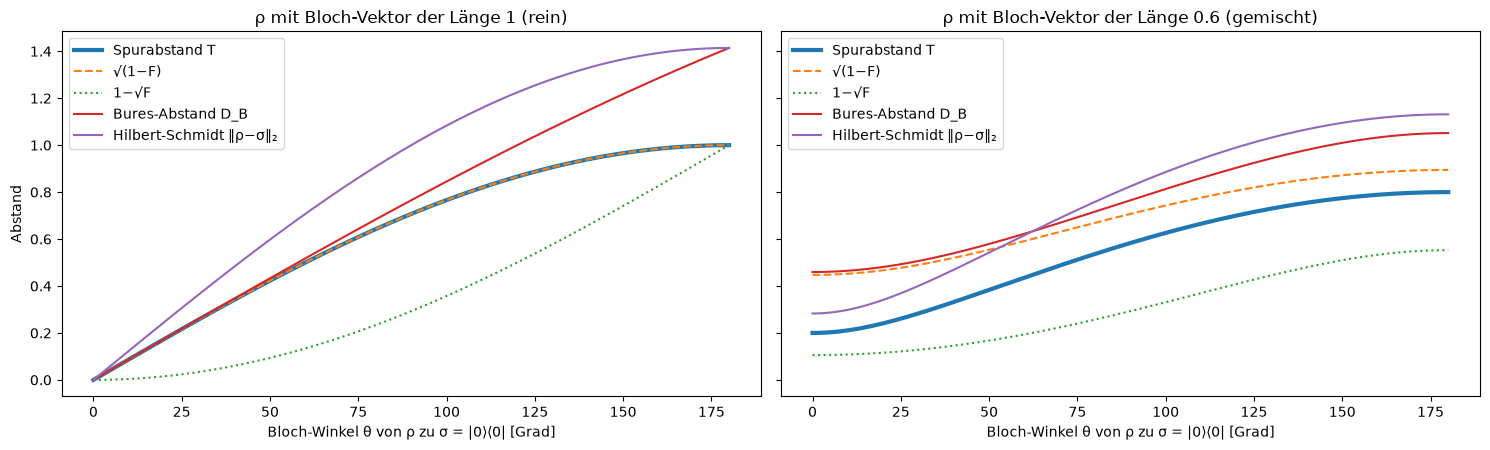

Qubit-Formel: T = 0.421793, ½|r − s| = 0.421793


In [2]:
p, q = rng.dirichlet(np.ones(4)), rng.dirichlet(np.ones(4))
rp, rq = np.diag(p).astype(complex), np.diag(q).astype(complex)
print(f"Spurabstand {spurabstand(rp, rq):.6f}  | TV-Abstand {0.5 * np.abs(p - q).sum():.6f}")
print(f"Fidelity    {fidelity(rp, rq):.6f}  | (Σ√(pq))²  {np.sum(np.sqrt(p * q)) ** 2:.6f}")
print(f"D(ρ||σ)     {rel_entropie(rp, rq):.6f}  | KL         {np.sum(p * np.log2(p / q)):.6f}")

sigma = dm([1, 0])
theta = np.linspace(0, np.pi, 181)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for ax, laenge in zip(axes, [1.0, 0.6]):
    werte = {k: [] for k in ["T", "sqrt(1-F)", "1-sqrt(F)", "D_B", "HS"]}
    for t in theta:
        rho = from_bloch(laenge * np.array([np.sin(t), 0, np.cos(t)]))
        F = fidelity(rho, sigma)
        werte["T"].append(spurabstand(rho, sigma)); werte["sqrt(1-F)"].append(np.sqrt(1 - F))
        werte["1-sqrt(F)"].append(1 - np.sqrt(F)); werte["D_B"].append(bures(rho, sigma))
        werte["HS"].append(hs_abstand(rho, sigma))
    ax.plot(np.degrees(theta), werte["T"], lw=3, label="Spurabstand T")
    ax.plot(np.degrees(theta), werte["sqrt(1-F)"], "--", label="√(1−F)")
    ax.plot(np.degrees(theta), werte["1-sqrt(F)"], ":", label="1−√F")
    ax.plot(np.degrees(theta), werte["D_B"], label="Bures-Abstand D_B")
    ax.plot(np.degrees(theta), werte["HS"], label="Hilbert-Schmidt ‖ρ−σ‖₂")
    ax.set_xlabel("Bloch-Winkel θ von ρ zu σ = |0⟩⟨0| [Grad]")
    ax.set_title(f"ρ mit Bloch-Vektor der Länge {laenge:g}" + (" (rein)" if laenge == 1 else " (gemischt)"))
    ax.legend()
axes[0].set_ylabel("Abstand")
plt.tight_layout()
plt.show()
r, s = 0.6 * np.array([np.sin(1.0), 0, np.cos(1.0)]), np.array([0, 0, 1.0])
print(f"Qubit-Formel: T = {spurabstand(from_bloch(r), from_bloch(s)):.6f}, ½|r − s| = {0.5 * np.linalg.norm(r - s):.6f}")

##### *2. Fuchs–van de Graaf und Pinsker an Zufallszuständen*

Liegen alle zufälligen Paare $(\rho,\sigma)$ in Dimension 2 bis 4 zwischen den Schranken $1 - \sqrt F\le T\le\sqrt{1-F}$, und gilt $D(\rho\Vert\sigma)\ge\tfrac2{\ln2}T^2$? Vorher überlegen: Wo liegen Paare reiner Zustände?

1 − √F ≤ T ≤ √(1−F) für alle Paare: True
reine Paare: größte Abweichung von T = √(1−F): 2.3e-15
Pinsker: kleinstes D − 2T²/ln2 = 0.0007 (≥ 0)


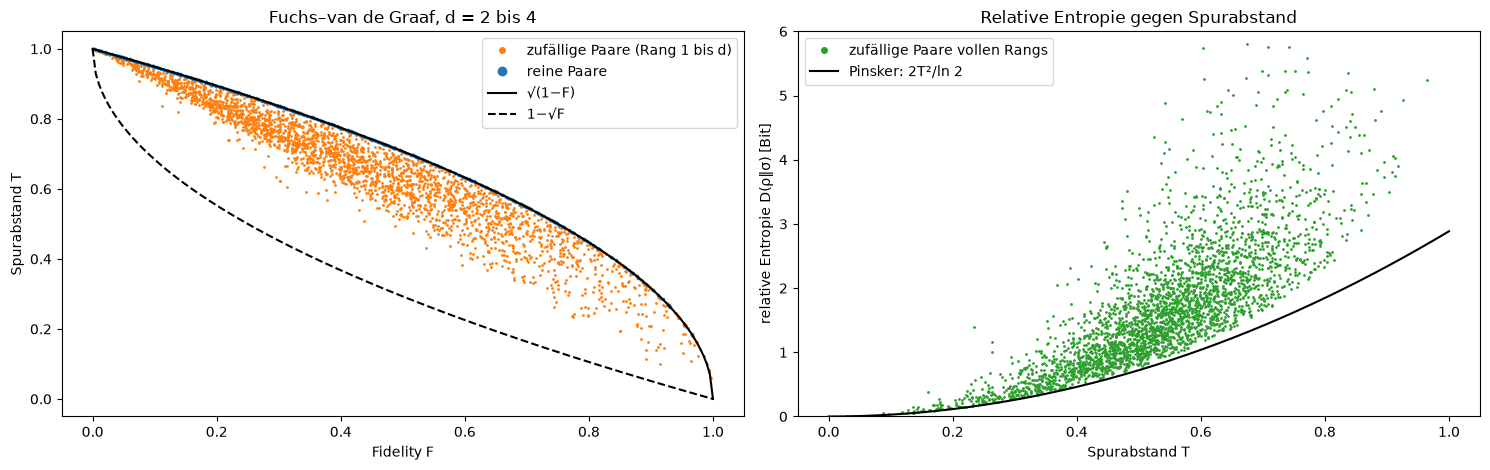

In [3]:
punkte_gemischt, punkte_rein, pinsker = [], [], []
for _ in range(3000):
    d = rng.integers(2, 5)
    rho, sigma = zufallszustand(d, rng.integers(1, d + 1)), zufallszustand(d, rng.integers(1, d + 1))
    punkte_gemischt.append((fidelity(rho, sigma), spurabstand(rho, sigma)))
    rho_v, sigma_v = zufallszustand(d), zufallszustand(d)                  # vollen Rangs: D ist endlich
    pinsker.append((spurabstand(rho_v, sigma_v), rel_entropie(rho_v, sigma_v)))
for _ in range(400):
    d = rng.integers(2, 5)
    a, c = zufallszustand(d, 1), zufallszustand(d, 1)
    punkte_rein.append((fidelity(a, c), spurabstand(a, c)))
pg, pr, pk = map(np.array, (punkte_gemischt, punkte_rein, pinsker))
print("1 − √F ≤ T ≤ √(1−F) für alle Paare:",
      np.all(pg[:, 1] >= 1 - np.sqrt(pg[:, 0]) - 1e-9) and np.all(pg[:, 1] <= np.sqrt(1 - pg[:, 0]) + 1e-9))
print(f"reine Paare: größte Abweichung von T = √(1−F): {np.max(abs(pr[:, 1] - np.sqrt(1 - pr[:, 0]))):.1e}")
print(f"Pinsker: kleinstes D − 2T²/ln2 = {np.min(pk[:, 1] - 2 * pk[:, 0] ** 2 / np.log(2)):.4f} (≥ 0)")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
F = np.linspace(0, 1, 200)
axes[0].plot(pg[:, 0], pg[:, 1], ".", ms=2, color="tab:orange", label="zufällige Paare (Rang 1 bis d)")
axes[0].plot(pr[:, 0], pr[:, 1], ".", ms=3, color="tab:blue", label="reine Paare")
axes[0].plot(F, np.sqrt(1 - F), "k-", label="√(1−F)")
axes[0].plot(F, 1 - np.sqrt(F), "k--", label="1−√F")
axes[0].set_xlabel("Fidelity F"); axes[0].set_ylabel("Spurabstand T")
axes[0].set_title("Fuchs–van de Graaf, d = 2 bis 4"); axes[0].legend(markerscale=4)
T = np.linspace(0, 1, 200)
axes[1].plot(pk[:, 0], pk[:, 1], ".", ms=2, color="tab:green", label="zufällige Paare vollen Rangs")
axes[1].plot(T, 2 * T ** 2 / np.log(2), "k-", label="Pinsker: 2T²/ln 2")
axes[1].set_xlabel("Spurabstand T"); axes[1].set_ylabel("relative Entropie D(ρ‖σ) [Bit]")
axes[1].set_ylim(0, 6)
axes[1].set_title("Relative Entropie gegen Spurabstand"); axes[1].legend(markerscale=4)
plt.tight_layout()
plt.show()

##### *3. Datenverarbeitung: Kanäle machen Zustände nie unterscheidbarer*

Für zufällige Paare und zufällige Kanäle: Ist das Verhältnis „nachher durch vorher“ für Spurabstand, Bures-Abstand und relative Entropie immer höchstens 1? Und für den Hilbert-Schmidt-Abstand? Zusätzlich das Gegenbeispiel aus Herleitung 3: $\rho\otimes I/d$ und $\sigma\otimes I/d$ unter der Partialspur.

Spurabstand       : größtes Verhältnis 0.9819, Anteil > 1: 0.000
Bures-Abstand     : größtes Verhältnis 0.9729, Anteil > 1: 0.000
relative Entropie : größtes Verhältnis 0.9366, Anteil > 1: 0.000
Hilbert-Schmidt   : größtes Verhältnis 1.1715, Anteil > 1: 0.002
Partialspur, d = 2: Hilbert-Schmidt nachher/vorher = 1.414 (√d = 1.414), Spurabstand nachher/vorher = 1.000
Partialspur, d = 4: Hilbert-Schmidt nachher/vorher = 2.000 (√d = 2.000), Spurabstand nachher/vorher = 1.000
Partialspur, d = 8: Hilbert-Schmidt nachher/vorher = 2.828 (√d = 2.828), Spurabstand nachher/vorher = 1.000


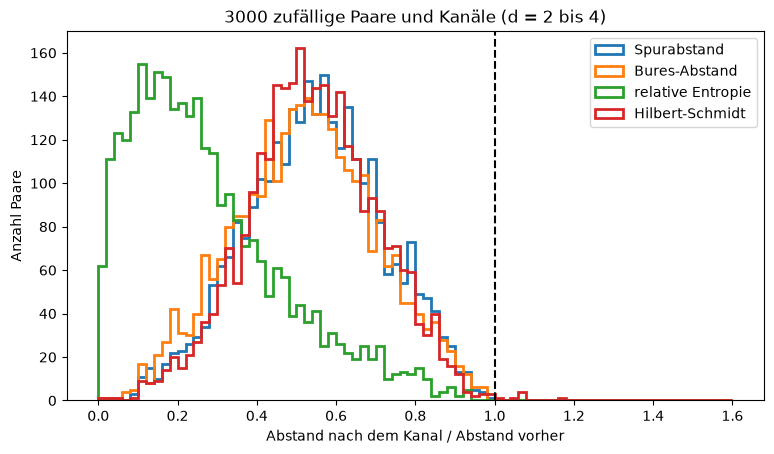

In [4]:
verhaeltnis = {"Spurabstand": [], "Bures-Abstand": [], "relative Entropie": [], "Hilbert-Schmidt": []}
for _ in range(3000):
    d_ein, d_aus = rng.integers(2, 5), rng.integers(2, 5)
    rho, sigma = zufallszustand(d_ein), zufallszustand(d_ein)
    K = zufallskanal(d_ein, d_aus, rng.integers(2, 5))          # mindestens 2 Kraus-Operatoren: kein reiner Basiswechsel
    r2, s2 = kanal(K, rho), kanal(K, sigma)
    verhaeltnis["Spurabstand"].append(spurabstand(r2, s2) / spurabstand(rho, sigma))
    verhaeltnis["Bures-Abstand"].append(bures(r2, s2) / bures(rho, sigma))
    verhaeltnis["relative Entropie"].append(rel_entropie(r2, s2) / rel_entropie(rho, sigma))
    verhaeltnis["Hilbert-Schmidt"].append(hs_abstand(r2, s2) / hs_abstand(rho, sigma))
for name, v in verhaeltnis.items():
    print(f"{name:18s}: größtes Verhältnis {max(v):.4f}, Anteil > 1: {np.mean(np.array(v) > 1 + 1e-9):.3f}")

# Gegenbeispiel: Partialspur über ein maximal gemischtes System der Dimension d
rho, sigma = zufallszustand(2), zufallszustand(2)
for d in [2, 4, 8]:
    vorher = hs_abstand(np.kron(rho, np.eye(d) / d), np.kron(sigma, np.eye(d) / d))
    print(f"Partialspur, d = {d}: Hilbert-Schmidt nachher/vorher = {hs_abstand(rho, sigma) / vorher:.3f} (√d = {np.sqrt(d):.3f}), "
          f"Spurabstand nachher/vorher = {spurabstand(rho, sigma) / spurabstand(np.kron(rho, np.eye(d) / d), np.kron(sigma, np.eye(d) / d)):.3f}")

fig, ax = plt.subplots(figsize=(9, 4.8))
bins = np.linspace(0, 1.6, 81)
for name, v in verhaeltnis.items():
    ax.hist(v, bins=bins, histtype="step", lw=2, label=name)
ax.axvline(1, color="k", ls="--")
ax.set_xlabel("Abstand nach dem Kanal / Abstand vorher"); ax.set_ylabel("Anzahl Paare")
ax.set_title("3000 zufällige Paare und Kanäle (d = 2 bis 4)"); ax.legend()
plt.show()

##### *4. Unterscheiden mit vielen Kopien: der Chernoff-Exponent*

Zwei gemischte Qubit-Zustände, gleiche Priors. Wie schnell fällt der kleinste Fehler $P_\text{err}^{(n)} = \tfrac12\big(1 - T(\rho^{\otimes n},\sigma^{\otimes n})\big)$ mit der Zahl $n$ der Kopien? Vorher überlegen: Bestimmt der Spurabstand einer Kopie die Steigung von $\ln P_\text{err}^{(n)}$?

$\rho^{\otimes n}$ ist eine $2^n$-dimensionale Matrix. Für große $n$ nutzt der Code die Permutationssymmetrie (Schur–Weyl-Dualität): $\rho^{\otimes n}$ zerfällt in Blöcke $\det(\rho)^k\,\mathrm{Sym}^{n-2k}(\rho)$ der Dimension $n - 2k + 1$, jeder mit der Vielfachheit $\binom nk - \binom n{k-1}$, und dieselbe Zerlegung gilt für $\sigma$. $\mathrm{Sym}^m$ ist die Wirkung auf dem symmetrischen Unterraum von $m$ Qubits, also auf Spin $m/2$. So bleibt die Rechnung auch für $n = 400$ klein; bis $n = 8$ wird sie gegen die direkte Rechnung geprüft.

T = 0.2915, F = 0.9150, Chernoff: Q = 0.9529 bei s = 0.499, ξ = 0.0482
zum Vergleich: −ln F = 0.0889, D(ρ‖σ) = 0.1946 nat, D(σ‖ρ) = 0.1964 nat
n = 2: direkt 0.334074137354, Blöcke 0.334074137354
n = 5: direkt 0.236034079366, Blöcke 0.236034079366
n = 8: direkt 0.185329573846, Blöcke 0.185329573846
−(1/n) ln P_err: n = 10 → 0.1842, n = 100 → 0.0705, n = 400 → 0.0556; ξ = 0.0482


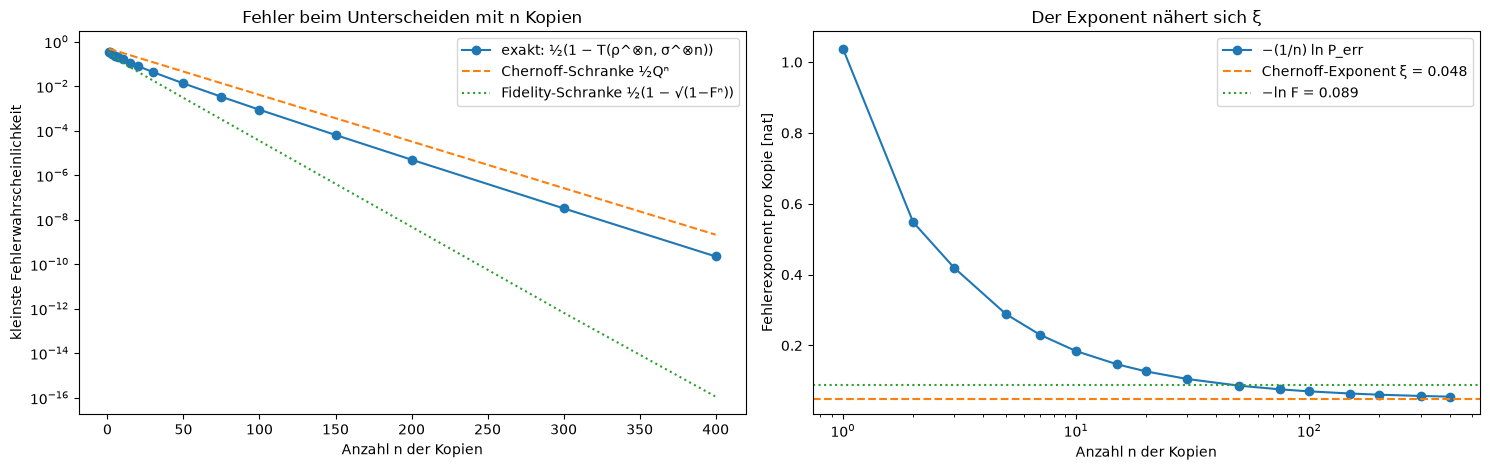

In [5]:
rho = from_bloch([0, 0, 0.6])
sigma = from_bloch([0.5, 0, 0.3])
s_werte = np.linspace(0, 1, 1001)
Q_s = np.array([np.trace(mfun(rho, lambda w: w ** s) @ mfun(sigma, lambda w: w ** (1 - s))).real for s in s_werte])
Q, s_opt = Q_s.min(), s_werte[Q_s.argmin()]
xi = -np.log(Q)
F1 = fidelity(rho, sigma)
print(f"T = {spurabstand(rho, sigma):.4f}, F = {F1:.4f}, Chernoff: Q = {Q:.4f} bei s = {s_opt:.3f}, ξ = {xi:.4f}")
print(f"zum Vergleich: −ln F = {-np.log(F1):.4f}, D(ρ‖σ) = {rel_entropie(rho, sigma) * np.log(2):.4f} nat, "
      f"D(σ‖ρ) = {rel_entropie(sigma, rho) * np.log(2):.4f} nat")


def spin_matrizen(m):
    """J_x, J_y, J_z für Spin j = m/2 in der Basis |m, i> (i Einsen, J_z = j − i)."""
    j = m / 2
    mz = j - np.arange(m + 1)
    j_plus = np.diag(np.sqrt(j * (j + 1) - mz[1:] * (mz[1:] + 1)), 1)
    return (j_plus + j_plus.T) / 2, (j_plus - j_plus.T) / 2j, np.diag(mz)


def p_err_kopien(rho, sigma, n):
    """½(1 − T(ρ^⊗n, σ^⊗n)) über die Schur–Weyl-Blöcke. In der Eigenbasis von ρ ist Sym^m(ρ) diagonal;
    Sym^m(σ) = S diag(μ-Potenzen) S† mit S = Sym^m(U) = exp(−i 2 h·J), wenn U = exp(−i h·σ) σ in diese Basis dreht."""
    lam, Vr = np.linalg.eigh(rho)
    mu, Vs = np.linalg.eigh(sigma)
    U = Vr.conj().T @ Vs
    U = U / np.sqrt(U[0, 0] * U[1, 1] - U[0, 1] * U[1, 0])      # globale Phase weg (Determinante 1): U in SU(2)
    w, Q_ = np.linalg.eig(U)
    H = (Q_ * (1j * np.log(w))) @ np.linalg.inv(Q_)            # U = exp(−iH)
    h = [np.trace(H @ P).real / 2 for P in (X, Y, Z)]
    summe = 0.0
    for k in range(n // 2 + 1):
        m = n - 2 * k
        i = np.arange(m + 1)
        log_vielfach = np.log(float(math.comb(n, k) - (math.comb(n, k - 1) if k else 0)))
        # Wurzeln der Diagonaleinträge, Vielfachheit eingerechnet (in Logarithmen, damit nichts überläuft)
        a = np.exp(0.5 * (log_vielfach + k * np.log(lam[0] * lam[1]) + (m - i) * np.log(lam[0]) + i * np.log(lam[1])))
        b = np.exp(0.5 * (log_vielfach + k * np.log(mu[0] * mu[1]) + (m - i) * np.log(mu[0]) + i * np.log(mu[1])))
        Jx, Jy, Jz = spin_matrizen(m)
        g, W = np.linalg.eigh(2 * (h[0] * Jx + h[1] * Jy + h[2] * Jz))
        S = (W * np.exp(-1j * g)) @ W.conj().T
        A, B = np.diag(a ** 2), (S * b ** 2) @ S.conj().T
        summe += 0.25 * (a @ a + b @ b - np.abs(np.linalg.eigvalsh(A - B)).sum())
    return summe


for n in [2, 5, 8]:
    direkt = 0.5 * (1 - spurabstand(functools.reduce(np.kron, [rho] * n), functools.reduce(np.kron, [sigma] * n)))
    print(f"n = {n}: direkt {direkt:.12f}, Blöcke {p_err_kopien(rho, sigma, n):.12f}")

n_werte = np.array([1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100, 150, 200, 300, 400])
P_err = np.array([p_err_kopien(rho, sigma, n) for n in n_werte])
rate = -np.log(P_err) / n_werte
print(f"−(1/n) ln P_err: n = 10 → {rate[5]:.4f}, n = 100 → {rate[11]:.4f}, n = 400 → {rate[-1]:.4f}; ξ = {xi:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].semilogy(n_werte, P_err, "o-", label="exakt: ½(1 − T(ρ^⊗n, σ^⊗n))")
axes[0].semilogy(n_werte, 0.5 * Q ** n_werte, "--", label="Chernoff-Schranke ½Qⁿ")
axes[0].semilogy(n_werte, 0.5 * (1 - np.sqrt(1 - F1 ** n_werte)), ":", label="Fidelity-Schranke ½(1 − √(1−Fⁿ))")
axes[0].set_xlabel("Anzahl n der Kopien"); axes[0].set_ylabel("kleinste Fehlerwahrscheinlichkeit")
axes[0].set_title("Fehler beim Unterscheiden mit n Kopien"); axes[0].legend()
axes[1].semilogx(n_werte, rate, "o-", label="−(1/n) ln P_err")
axes[1].axhline(xi, color="tab:orange", ls="--", label=f"Chernoff-Exponent ξ = {xi:.3f}")
axes[1].axhline(-np.log(F1), color="tab:green", ls=":", label=f"−ln F = {-np.log(F1):.3f}")
axes[1].set_xlabel("Anzahl n der Kopien"); axes[1].set_ylabel("Fehlerexponent pro Kopie [nat]")
axes[1].set_title("Der Exponent nähert sich ξ"); axes[1].legend()
plt.tight_layout()
plt.show()

##### *5. Entropien: Rényi-Familie, bedingte Entropie, starke Subadditivität*

Wie hängt $S_\alpha$ von $\alpha$ ab? Wie verteilt sich die bedingte Entropie $S(A\vert B)$ für zufällige Zustände zweier Qubits, und hält die starke Subadditivität für zufällige Zustände dreier Qubits? Vorher überlegen: Warum ist $S(A\vert B)$ für reine Zustände nie positiv?

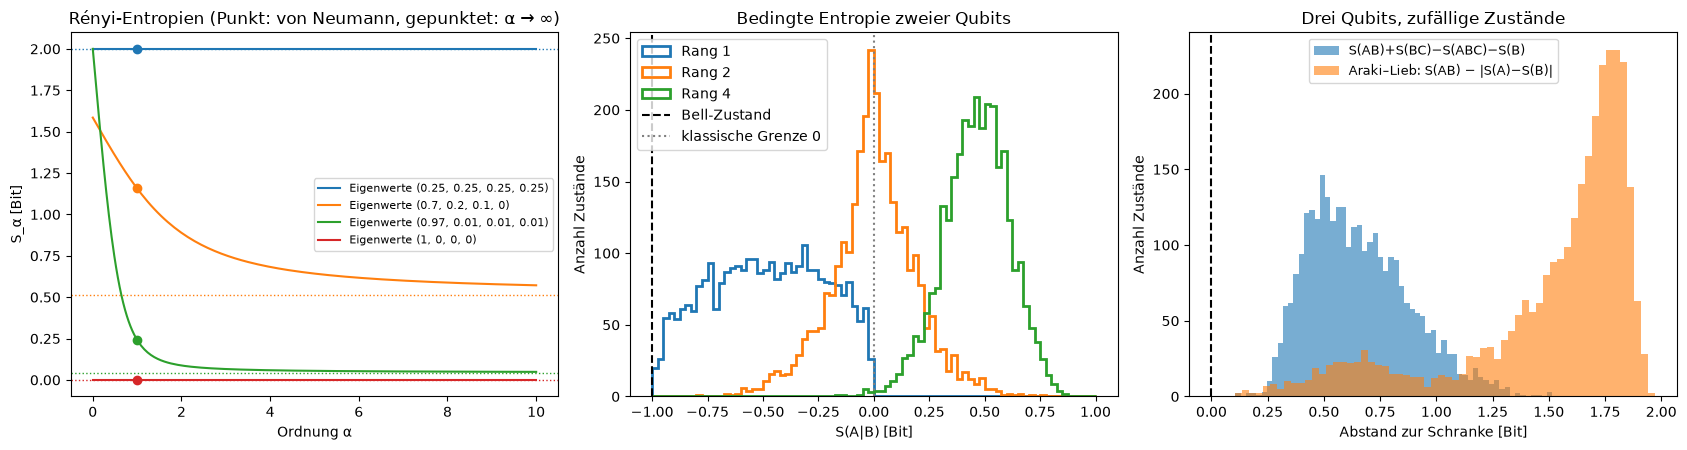

kleinster Wert: starke Subadditivität 1.06e-01, Araki–Lieb 1.06e-01


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

alphas = np.concatenate([np.linspace(0, 0.99, 50), np.linspace(1.01, 10, 120)])
for spektrum in [(0.25, 0.25, 0.25, 0.25), (0.7, 0.2, 0.1, 0), (0.97, 0.01, 0.01, 0.01), (1, 0, 0, 0)]:
    rho = np.diag(spektrum).astype(complex)
    linie, = axes[0].plot(alphas, [renyi(rho, a) for a in alphas], label=f"Eigenwerte {spektrum}")
    axes[0].plot(1, renyi(rho, 1), "o", color=linie.get_color())
    axes[0].axhline(renyi(rho, np.inf), color=linie.get_color(), ls=":", lw=1)
axes[0].set_xlabel("Ordnung α"); axes[0].set_ylabel("S_α [Bit]")
axes[0].set_title("Rényi-Entropien (Punkt: von Neumann, gepunktet: α → ∞)"); axes[0].legend(fontsize=8)

dims2 = [2, 2]
for rang, farbe in [(1, "tab:blue"), (2, "tab:orange"), (4, "tab:green")]:
    werte = []
    for _ in range(3000):
        rho = zufallszustand(4, rang)
        werte.append(entropie(rho) - entropie(partialspur(rho, dims2, [1])))
    axes[1].hist(werte, bins=np.linspace(-1, 1, 81), histtype="step", lw=2, color=farbe, label=f"Rang {rang}")
bell = dm([1, 0, 0, 1])
axes[1].axvline(entropie(bell) - entropie(partialspur(bell, dims2, [1])), color="k", ls="--", label="Bell-Zustand")
axes[1].axvline(0, color="0.5", ls=":", label="klassische Grenze 0")
axes[1].set_xlabel("S(A|B) [Bit]"); axes[1].set_ylabel("Anzahl Zustände")
axes[1].set_title("Bedingte Entropie zweier Qubits"); axes[1].legend()

dims3 = [2, 2, 2]
ssa, al = [], []
for _ in range(3000):
    rho = zufallszustand(8, rng.integers(1, 9))
    S = lambda behalten: entropie(partialspur(rho, dims3, behalten))
    ssa.append(S([0, 1]) + S([1, 2]) - S([0, 1, 2]) - S([1]))
    al.append(S([0, 1]) - abs(S([0]) - S([1])))
axes[2].hist(ssa, bins=60, alpha=0.6, label="S(AB)+S(BC)−S(ABC)−S(B)")
axes[2].hist(al, bins=60, alpha=0.6, label="Araki–Lieb: S(AB) − |S(A)−S(B)|")
axes[2].axvline(0, color="k", ls="--")
axes[2].set_xlabel("Abstand zur Schranke [Bit]"); axes[2].set_ylabel("Anzahl Zustände")
axes[2].set_title("Drei Qubits, zufällige Zustände"); axes[2].legend(fontsize=9)
plt.tight_layout()
plt.show()
print(f"kleinster Wert: starke Subadditivität {min(ssa):.2e}, Araki–Lieb {min(al):.2e}")

##### *6. Schumacher-Kompression*

Ein Qubit-Zustand mit Eigenwerten $0.9$ und $0.1$ hat $S = h(0.1) = 0.469$ Bit. Wie viele Qubits pro Kopie braucht der kleinste Unterraum, der von $\rho^{\otimes n}$ das Gewicht $1 - \varepsilon$ erfasst? Vorher vorhersagen: von welcher Seite nähert sich die Kurve $S$, und wie schnell?

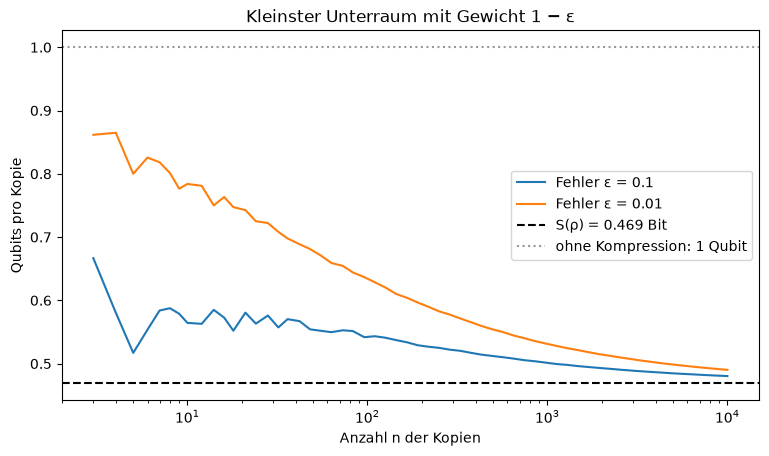

n = 12, ε = 0.01: direkt 0.7811 Qubits pro Kopie, Formel 0.7811
n = 10 000: ε = 0.1 → 0.4803, ε = 0.01 → 0.4902 (S = 0.4690)


In [7]:
p_min = 0.1                                                    # kleinerer Eigenwert
S_rho = h2(p_min)


def qubits_pro_kopie(n, eps):
    """log2(kleinste Dimension, die vom Gewicht von ρ^⊗n mindestens 1 − eps erfasst) / n.
    Die Eigenwerte (1−p)^(n−k) p^k mit Vielfachheit C(n, k) fallen mit k; man füllt von k = 0 an auf."""
    k = np.arange(n + 1)
    gewicht = binom.cdf(k, n, p_min)                           # Gewicht der Blöcke 0..k
    K = np.searchsorted(gewicht, 1 - eps)                      # erster Block, mit dem 1 − eps erreicht wird
    log_comb = gammaln(n + 1) - gammaln(k + 1) - gammaln(n - k + 1)
    log_lam = (n - K) * np.log(1 - p_min) + K * np.log(p_min)
    fehlt = (1 - eps) - (gewicht[K - 1] if K > 0 else 0)
    log_rest = np.log(fehlt) - log_lam                         # so viele Eigenvektoren braucht der angebrochene Block
    teile = list(log_comb[:K]) + [np.log(np.ceil(np.exp(log_rest))) if log_rest < 30 else log_rest]
    return np.logaddexp.reduce(teile) / np.log(2) / n


n_werte = np.unique(np.logspace(0.5, 4, 60).astype(int))
fig, ax = plt.subplots(figsize=(9, 4.8))
for eps in [0.1, 0.01]:
    ax.semilogx(n_werte, [qubits_pro_kopie(n, eps) for n in n_werte], label=f"Fehler ε = {eps:g}")
ax.axhline(S_rho, color="k", ls="--", label=f"S(ρ) = {S_rho:.3f} Bit")
ax.axhline(1, color="0.6", ls=":", label="ohne Kompression: 1 Qubit")
ax.set_xlabel("Anzahl n der Kopien"); ax.set_ylabel("Qubits pro Kopie")
ax.set_title("Kleinster Unterraum mit Gewicht 1 − ε"); ax.legend()
plt.show()

# Kontrolle bei n = 12 durch direkte Diagonalisierung von ρ^⊗12
n = 12
w = np.sort(np.linalg.eigvalsh(functools.reduce(np.kron, [np.diag([1 - p_min, p_min])] * n)))[::-1]
dim = np.searchsorted(np.cumsum(w), 1 - 0.01) + 1
print(f"n = 12, ε = 0.01: direkt {np.log2(dim) / n:.4f} Qubits pro Kopie, Formel {qubits_pro_kopie(n, 0.01):.4f}")
print(f"n = 10 000: ε = 0.1 → {qubits_pro_kopie(10_000, 0.1):.4f}, ε = 0.01 → {qubits_pro_kopie(10_000, 0.01):.4f} (S = {S_rho:.4f})")

##### *7. Holevo-Schranke und Accessible Information*

Wie viel klassische Information lässt sich aus zwei nicht orthogonalen reinen Zuständen, aus der Trine und aus dem Tetraeder auslesen, verglichen mit der Holevo-Größe $\chi$? Die Accessible Information wird numerisch über alle POVMs mit sechs Elementen vom Rang 1 maximiert (30 zufällige Starts). Vorher vorhersagen: Ist bei der Trine die Trine-Messung selbst optimal?

Trine    : chi 1.0000, eigene 0.3333, anti 0.5850, numerisch 0.5850
Tetraeder: chi 1.0000, eigene 0.2075, anti 0.4150, numerisch 0.4150
Erwartet: Trine log₂3 − 1 = 0.5850, Tetraeder 2 − log₂3 = 0.4150


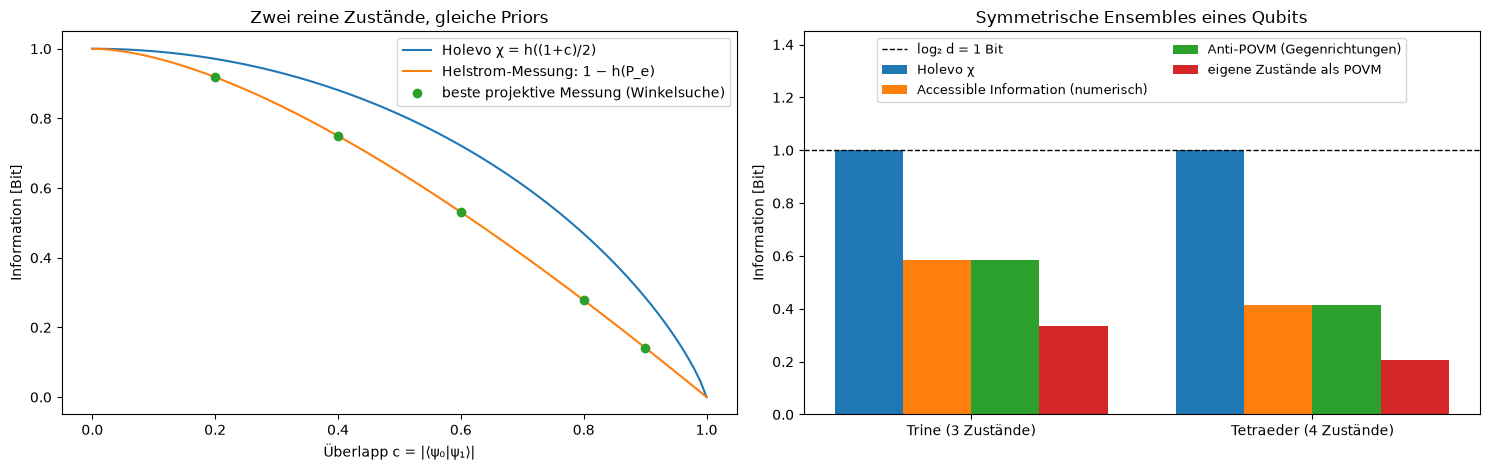

In [8]:
def wechselinfo(zustaende, ps, E):
    """I(X:Y) in Bit für das Ensemble {p_x, ρ_x} und das POVM E."""
    pxy = np.array(ps)[:, None] * np.array([[np.trace(e @ r).real for e in E] for r in zustaende])
    py = pxy.sum(axis=0)
    m = pxy > 1e-15
    return np.sum(pxy[m] * np.log2(pxy[m] / (np.array(ps)[:, None] * py[None, :])[m]))


def holevo(zustaende, ps):
    return entropie(sum(p * r for p, r in zip(ps, zustaende))) - sum(p * entropie(r) for p, r in zip(ps, zustaende))


def povm_aus_parametern(x, K=6, d=2):
    """Rang-1-POVM E_k = S^(−1/2) |v_k><v_k| S^(−1/2) mit S = Σ|v_k><v_k| (immer gültig)."""
    v = (x[:K * d] + 1j * x[K * d:]).reshape(K, d)
    B = [np.outer(a, a.conj()) for a in v]
    S_inv = mfun(sum(B), lambda w: 1 / np.sqrt(w))
    return [S_inv @ c @ S_inv for c in B]


def accessible_information(zustaende, ps, starts=30):
    beste = 0
    for _ in range(starts):
        erg = minimize(lambda x: -wechselinfo(zustaende, ps, povm_aus_parametern(x)), rng.normal(size=24), method="BFGS")
        beste = max(beste, -erg.fun)
    return beste


# (a) zwei reine Zustände mit Überlapp c
c_werte = np.linspace(0, 1, 101)
chi_2 = h2((1 + c_werte) / 2)
P_e = 0.5 * (1 - np.sqrt(1 - c_werte ** 2))
I_helstrom = 1 - h2(P_e)
c_test, I_scan = [0.2, 0.4, 0.6, 0.8, 0.9], []
for c in c_test:
    halb = np.arccos(c)                                        # Bloch-Winkel ±halb ergibt Überlapp c
    zust = [from_bloch([np.sin(a), 0, np.cos(a)]) for a in (halb, -halb)]
    I_scan.append(max(wechselinfo(zust, [0.5, 0.5], [from_bloch([np.sin(phi), 0, np.cos(phi)]),
                                                       from_bloch([-np.sin(phi), 0, -np.cos(phi)])])
                      for phi in np.linspace(0, np.pi, 721)))

# (b) Trine und Tetraeder
n_trine = [np.array([np.sin(a), 0, np.cos(a)]) for a in 2 * np.pi * np.arange(3) / 3]
n_tetra = [np.array([0, 0, 1.0])] + [np.array([np.sqrt(8) / 3 * np.cos(b), np.sqrt(8) / 3 * np.sin(b), -1 / 3])
                                     for b in 2 * np.pi * np.arange(3) / 3]
ergebnis = {}
for name, richtungen in [("Trine", n_trine), ("Tetraeder", n_tetra)]:
    zust = [from_bloch(v) for v in richtungen]
    ps = [1 / len(zust)] * len(zust)
    eigene = [2 / len(zust) * r for r in zust]                 # die Zustände selbst als POVM (Trine bzw. SIC)
    anti = [2 / len(zust) * from_bloch(-v) for v in richtungen]  # die Gegenrichtungen als POVM
    ergebnis[name] = dict(chi=holevo(zust, ps), eigene=wechselinfo(zust, ps, eigene),
                          anti=wechselinfo(zust, ps, anti), numerisch=accessible_information(zust, ps))
    print(f"{name:9s}: " + ", ".join(f"{k} {v:.4f}" for k, v in ergebnis[name].items()))
print(f"Erwartet: Trine log₂3 − 1 = {np.log2(3) - 1:.4f}, Tetraeder 2 − log₂3 = {2 - np.log2(3):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].plot(c_werte, chi_2, label="Holevo χ = h((1+c)/2)")
axes[0].plot(c_werte, I_helstrom, label="Helstrom-Messung: 1 − h(P_e)")
axes[0].plot(c_test, I_scan, "o", label="beste projektive Messung (Winkelsuche)")
axes[0].set_xlabel("Überlapp c = |⟨ψ₀|ψ₁⟩|"); axes[0].set_ylabel("Information [Bit]")
axes[0].set_title("Zwei reine Zustände, gleiche Priors"); axes[0].legend()
namen = ["chi", "numerisch", "anti", "eigene"]
beschriftung = ["Holevo χ", "Accessible Information (numerisch)", "Anti-POVM (Gegenrichtungen)", "eigene Zustände als POVM"]
x = np.arange(2)
for i, (k, lab) in enumerate(zip(namen, beschriftung)):
    axes[1].bar(x + (i - 1.5) * 0.2, [ergebnis[n][k] for n in ("Trine", "Tetraeder")], 0.2, label=lab)
axes[1].axhline(1, color="k", ls="--", lw=1, label="log₂ d = 1 Bit")
axes[1].set_ylim(0, 1.45)
axes[1].set_xticks(x); axes[1].set_xticklabels(["Trine (3 Zustände)", "Tetraeder (4 Zustände)"])
axes[1].set_ylabel("Information [Bit]"); axes[1].set_title("Symmetrische Ensembles eines Qubits")
axes[1].legend(fontsize=9, ncol=2, loc="upper center")
plt.tight_layout()
plt.show()

##### *8. No-Cloning: die beste Klonmaschine und No-Signalling*

Wie gut sind die beiden Kopien der Bužek–Hillery-Maschine, verglichen mit einer CNOT-Kopie in der z-Basis? Und ändert eine Operation von Alice an einem verschränkten Zustand den reduzierten Zustand von Bob? Vorher vorhersagen: Für welchen Eingang ist die CNOT-Kopie perfekt, für welchen am schlechtesten?

Isometrie V†V = I: True
Kopie 1 = Kopie 2 = (2/3)ψ + (1/6)I: True, F = 0.8333
Kopie 1 = Kopie 2 = (2/3)ψ + (1/6)I: True, F = 0.8333
Kopie 1 = Kopie 2 = (2/3)ψ + (1/6)I: True, F = 0.8333
Mittel über die Kugel: Bužek–Hillery 0.8333, CNOT-Kopie 0.6667


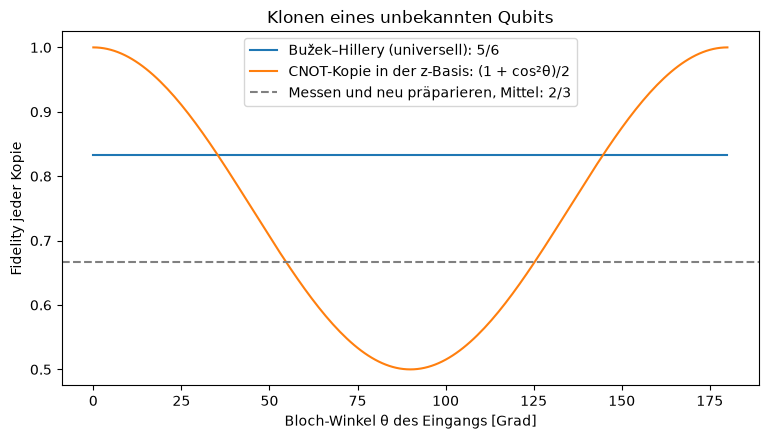

Bob nach Alices Kanal: Spurabstand zu vorher 1.4e-16
Alice misst σ_z: Bobs bedingter Zustand (Ergebnis 0) weicht um T = 0.271 ab, das Mittel über beide Ergebnisse um 0.0e+00


In [9]:
# Bužek–Hillery als Isometrie: Eingang (Qubit) → Kopie 1 ⊗ Kopie 2 ⊗ Maschine
ket = lambda *bits: np.eye(8)[int("".join(map(str, bits)), 2)]        # |Kopie 1, Kopie 2, Maschine>, Maschine 0 = ↑
V = np.zeros((8, 2))
V[:, 0] = np.sqrt(2 / 3) * ket(0, 0, 0) + np.sqrt(1 / 6) * (ket(0, 1, 1) + ket(1, 0, 1))
V[:, 1] = np.sqrt(2 / 3) * ket(1, 1, 1) + np.sqrt(1 / 6) * (ket(0, 1, 0) + ket(1, 0, 0))
print("Isometrie V†V = I:", np.allclose(V.T @ V, np.eye(2)))

for _ in range(3):
    psi = rng.normal(size=2) + 1j * rng.normal(size=2); psi /= np.linalg.norm(psi)
    aus = dm(V @ psi)
    r1, r2 = partialspur(aus, [2, 2, 2], [0]), partialspur(aus, [2, 2, 2], [1])
    print(f"Kopie 1 = Kopie 2 = (2/3)ψ + (1/6)I: {np.allclose(r1, r2) and np.allclose(r1, 2 / 3 * dm(psi) + I2 / 6)}, "
          f"F = {np.real(psi.conj() @ r1 @ psi):.4f}")

theta = np.linspace(0, np.pi, 181)
F_bh, F_cnot = [], []
CNOT = np.eye(4)[[0, 1, 3, 2]]
for t in theta:
    psi = np.array([np.cos(t / 2), np.sin(t / 2)])
    F_bh.append(np.real(psi @ partialspur(dm(V @ psi), [2, 2, 2], [0]) @ psi))
    F_cnot.append(np.real(psi @ partialspur(dm(CNOT @ np.kron(psi, [1, 0])), [2, 2], [0]) @ psi))
gewicht = np.sin(theta) / np.sum(np.sin(theta))                # Mittel über die Kugel
print(f"Mittel über die Kugel: Bužek–Hillery {np.sum(gewicht * F_bh):.4f}, CNOT-Kopie {np.sum(gewicht * F_cnot):.4f}")

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(np.degrees(theta), F_bh, label="Bužek–Hillery (universell): 5/6")
ax.plot(np.degrees(theta), F_cnot, label="CNOT-Kopie in der z-Basis: (1 + cos²θ)/2")
ax.axhline(2 / 3, color="0.5", ls="--", label="Messen und neu präparieren, Mittel: 2/3")
ax.set_xlabel("Bloch-Winkel θ des Eingangs [Grad]"); ax.set_ylabel("Fidelity jeder Kopie")
ax.set_title("Klonen eines unbekannten Qubits"); ax.legend()
plt.show()

# No-Signalling: Alice wendet einen zufälligen Kanal an oder misst; Bobs reduzierter Zustand bleibt gleich
rho_ab = zufallszustand(4, 1)                                  # rein, im Allgemeinen verschränkt
rho_b = partialspur(rho_ab, [2, 2], [1])
K = zufallskanal(2, 2, 3)
nach = sum(np.kron(Ka, I2) @ rho_ab @ np.kron(Ka, I2).conj().T for Ka in K)
print(f"Bob nach Alices Kanal: Spurabstand zu vorher {spurabstand(partialspur(nach, [2, 2], [1]), rho_b):.1e}")
P0 = np.kron(dm([1, 0]), I2)
p0 = np.trace(P0 @ rho_ab).real
bedingt0 = partialspur(P0 @ rho_ab @ P0, [2, 2], [1]) / p0
print(f"Alice misst σ_z: Bobs bedingter Zustand (Ergebnis 0) weicht um T = {spurabstand(bedingt0, rho_b):.3f} ab, "
      f"das Mittel über beide Ergebnisse um {spurabstand(partialspur(P0 @ rho_ab @ P0 + (np.eye(4) - P0) @ rho_ab @ (np.eye(4) - P0), [2, 2], [1]), rho_b):.1e}")

##### *9. Quanten-Fisher-Information: Standard-Quantenlimit und Heisenberg-Limit*

$N$ Qubits messen eine Phase $\theta$ über $e^{-i\theta G}$ mit $G = \tfrac12\sum_i\sigma_z^{(i)}$. Wie wächst $F_Q$ mit $N$ für Produkt- und GHZ-Zustände, mit und ohne Dephasierung $p = 0.05$ pro Qubit? $F_Q$ wird auf zwei Wegen berechnet: aus dem Bures-Abstand benachbarter Zustände und exakt aus der Eigenzerlegung von $\rho$. Vorher vorhersagen: Ab welchem $N$ verliert GHZ mit Dephasierung gegen den Produktzustand?

Produkt  p = 0.0: F_Q exakt [1. 2. 3. 4. 5. 6. 7. 8.]; größte Abweichung Bures 1.5e-03
GHZ      p = 0.0: F_Q exakt [ 1.  4.  9. 16. 25. 36. 49. 64.]; größte Abweichung Bures 3.4e-02
Produkt  p = 0.05: F_Q exakt [0.81 1.62 2.43 3.24 4.05 4.86 5.67 6.48]; größte Abweichung Bures 1.0e-03
GHZ      p = 0.05: F_Q exakt [ 0.81   2.624  4.783  6.887  8.717 10.167 11.21  11.859]; größte Abweichung Bures 2.2e-02


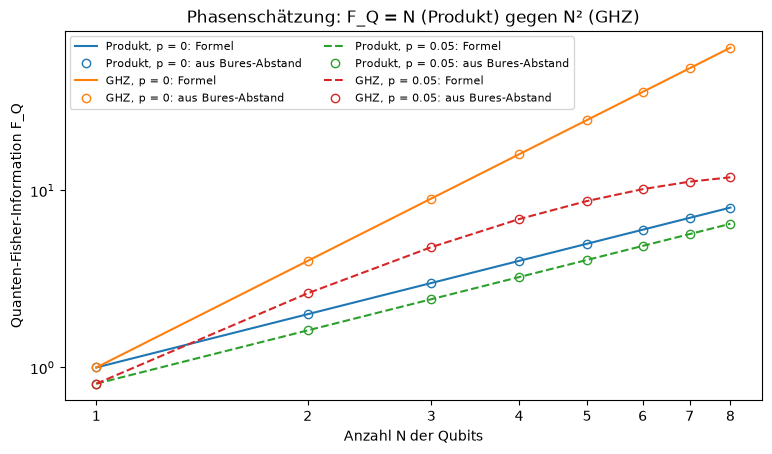

In [10]:
def qfi_exakt(rho, G):
    """F_Q = 2 Σ_ij (λ_i − λ_j)²/(λ_i + λ_j) |<i|G|j>|² für ρ_θ = e^(−iθG) ρ e^(iθG)."""
    lam, V = np.linalg.eigh(rho)
    Gm = V.conj().T @ G @ V
    L = lam[:, None] + lam[None, :]
    maske = L > 1e-12
    return 2 * np.sum(((lam[:, None] - lam[None, :]) ** 2 / np.where(maske, L, 1)) * np.abs(Gm) ** 2 * maske)


def qfi_bures(rho, G, delta=0.02):
    """F_Q aus D_B² = ¼ F_Q δ², also F_Q = 8(1 − √F)/δ²."""
    U = np.diag(np.exp(-1j * delta * np.diag(G)))              # G ist diagonal
    return 8 * (1 - np.sqrt(fidelity(rho, U @ rho @ U.conj().T))) / delta ** 2


def dephasiert(rho, n, p):
    """Lokale Dephasierung (1−p)ρ + p ZρZ auf jedem Qubit: ρ_ab wird mit (1−2p)^Hamming(a, b) multipliziert."""
    idx = np.arange(2 ** n)
    hamming = np.array([[bin(a ^ c).count("1") for c in idx] for a in idx])
    return rho * (1 - 2 * p) ** hamming


N_werte = np.arange(1, 9)
ergebnisse = {}
for p in [0.0, 0.05]:
    for name in ["Produkt", "GHZ"]:
        exakt, bures_ = [], []
        for N in N_werte:
            G = np.diag([0.5 * (N - 2 * bin(a).count("1")) for a in range(2 ** N)]).astype(complex)
            if name == "Produkt":
                psi = functools.reduce(np.kron, [np.array([1, 1]) / np.sqrt(2)] * N)
            else:
                psi = np.zeros(2 ** N); psi[[0, -1]] = 1 / np.sqrt(2)
            rho = dephasiert(dm(psi), N, p)
            exakt.append(qfi_exakt(rho, G)); bures_.append(qfi_bures(rho, G))
        ergebnisse[(name, p)] = (np.array(exakt), np.array(bures_))
        print(f"{name:8s} p = {p}: F_Q exakt {np.round(exakt, 3)}; größte Abweichung Bures {np.max(abs(np.array(bures_) - exakt)):.1e}")

fig, ax = plt.subplots(figsize=(9, 4.8))
formel = {("Produkt", 0.0): N_werte, ("GHZ", 0.0): N_werte ** 2,
          ("Produkt", 0.05): N_werte * 0.9 ** 2, ("GHZ", 0.05): N_werte ** 2 * 0.9 ** (2 * N_werte)}
for (name, p), (exakt, bures_) in ergebnisse.items():
    linie, = ax.plot(N_werte, formel[(name, p)], "-" if p == 0 else "--", label=f"{name}, p = {p:g}: Formel")
    ax.plot(N_werte, bures_, "o", color=linie.get_color(), mfc="none", label=f"{name}, p = {p:g}: aus Bures-Abstand")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks(N_werte, [str(N) for N in N_werte]); ax.minorticks_off()
ax.set_xlabel("Anzahl N der Qubits"); ax.set_ylabel("Quanten-Fisher-Information F_Q")
ax.set_title("Phasenschätzung: F_Q = N (Produkt) gegen N² (GHZ)"); ax.legend(fontsize=8, ncol=2)
plt.show()

##### *10. Abstände zwischen Kanälen: Diamantnorm gegen mittlere Fidelity*

Wie unterscheiden sich kohärente Fehler (Überrotation $e^{-i\varepsilon\sigma_z/2}$) und inkohärente Fehler (Depolarisation, Amplitudendämpfung) in der Diamantnorm, wenn sie dieselbe mittlere Fehlerrate $r = 1 - F_\text{avg}$ haben? Erst die SDP an zwei Fällen mit bekannter Lösung prüfen, auch die Frage, ob die Ancilla hilft.

Überrotation ε = 0.2: SDP 0.09983, ohne Ancilla 0.09980, sin(ε/2) = 0.09983
Depolarisation p = 0.1: SDP 0.07500 (3p/4 = 0.075), ohne Ancilla 0.05000 (p/2 = 0.05)
Überrotation (kohärent) : r = 1e-4 → ½‖·‖◇ ≈ 1.22e-02
Depolarisation          : r = 1e-4 → ½‖·‖◇ ≈ 1.50e-04
Amplitudendämpfung      : r = 1e-4 → ½‖·‖◇ ≈ 3.00e-04


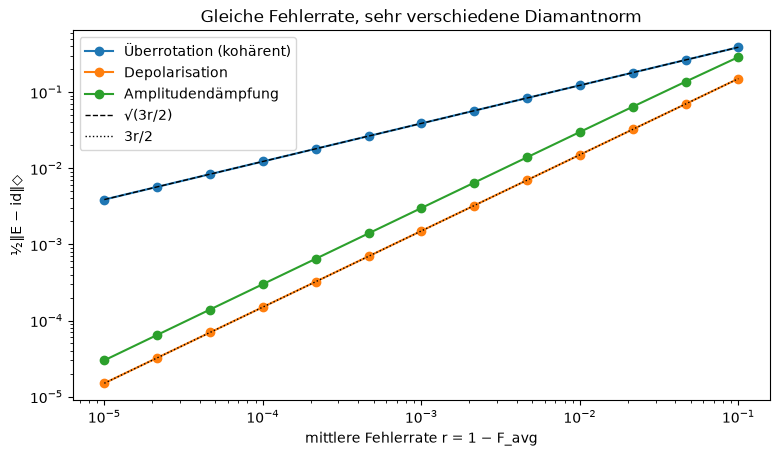

In [11]:
def diamant_halb(K1, K2, d=2):
    """½||E1 − E2||_◇ als SDP (Watrous): max Tr(J W) unter 0 ≤ W ≤ ρ ⊗ I, ρ Dichtematrix."""
    J = choi(K1, d) - choi(K2, d)
    W = cp.Variable((d * d, d * d), hermitian=True)
    r = cp.Variable((d, d), hermitian=True)
    nb = [W >> 0, cp.kron(r, np.eye(d)) - W >> 0, r >> 0, cp.trace(r) == 1]
    problem = cp.Problem(cp.Maximize(cp.real(cp.trace(J @ W))), nb)
    problem.solve()
    return problem.value


def ohne_ancilla(K1, K2, gitter=60):
    """Bester Spurabstand der Ausgänge über reine Eingänge ohne Ancilla (Gitter auf der Bloch-Kugel)."""
    beste = 0
    for t in np.linspace(0, np.pi, gitter):
        for ph in np.linspace(0, 2 * np.pi, 2 * gitter, endpoint=False):
            rho = dm([np.cos(t / 2), np.exp(1j * ph) * np.sin(t / 2)])
            beste = max(beste, spurabstand(kanal(K1, rho), kanal(K2, rho)))
    return beste


def r_mittel(K, d=2):
    F_pro = sum(abs(np.trace(k)) ** 2 for k in K) / d ** 2
    return 1 - (d * F_pro + 1) / (d + 1)


rotation = lambda eps: [np.diag([np.exp(-1j * eps / 2), np.exp(1j * eps / 2)])]
depol = lambda p: [np.sqrt(1 - 3 * p / 4) * I2] + [np.sqrt(p / 4) * P for P in (X, Y, Z)]
ampdaempf = lambda g: [np.array([[1, 0], [0, np.sqrt(1 - g)]], dtype=complex), np.array([[0, np.sqrt(g)], [0, 0]], dtype=complex)]
ID = [I2]
print(f"Überrotation ε = 0.2: SDP {diamant_halb(ID, rotation(0.2)):.5f}, ohne Ancilla {ohne_ancilla(ID, rotation(0.2)):.5f}, "
      f"sin(ε/2) = {np.sin(0.1):.5f}")
print(f"Depolarisation p = 0.1: SDP {diamant_halb(ID, depol(0.1)):.5f} (3p/4 = 0.075), ohne Ancilla {ohne_ancilla(ID, depol(0.1)):.5f} (p/2 = 0.05)")

r_ziel = np.logspace(-5, -1, 13)
kurven = {"Überrotation (kohärent)": lambda r: rotation(2 * np.arcsin(np.sqrt(1.5 * r))),
          "Depolarisation": lambda r: depol(2 * r),
          "Amplitudendämpfung": lambda r: ampdaempf(brentq(lambda g: r_mittel(ampdaempf(g)) - r, 0, 1))}
fig, ax = plt.subplots(figsize=(9, 4.8))
for name, fehlerkanal in kurven.items():
    rs, ds = [], []
    for r in r_ziel:
        K = fehlerkanal(r)
        rs.append(r_mittel(K)); ds.append(diamant_halb(ID, K))
    ax.loglog(rs, ds, "o-", label=name)
    print(f"{name:24s}: r = 1e-4 → ½‖·‖◇ ≈ {np.interp(np.log(1e-4), np.log(rs), ds):.2e}")
ax.loglog(r_ziel, np.sqrt(1.5 * r_ziel), "k--", lw=1, label="√(3r/2)")
ax.loglog(r_ziel, 1.5 * r_ziel, "k:", lw=1, label="3r/2")
ax.set_xlabel("mittlere Fehlerrate r = 1 − F_avg"); ax.set_ylabel("½‖E − id‖◇")
ax.set_title("Gleiche Fehlerrate, sehr verschiedene Diamantnorm"); ax.legend()
plt.show()

##### *11. Kanalkapazitäten*

Wie viele klassische Bits ($C$), wie viele Qubits ($Q$) und wie viele klassische Bits mit vorher geteilter Verschränkung ($C_E$) überträgt der depolarisierende Kanal $\rho\mapsto(1-p)\rho + pI/2$ pro Nutzung, und wie die Amplitudendämpfung? Alle Größen werden aus den Matrizen der Kanäle berechnet, nicht aus den geschlossenen Formeln. Vorher überlegen: Warum ist $C_E$ größer als $C$, und wo wird $Q$ null?

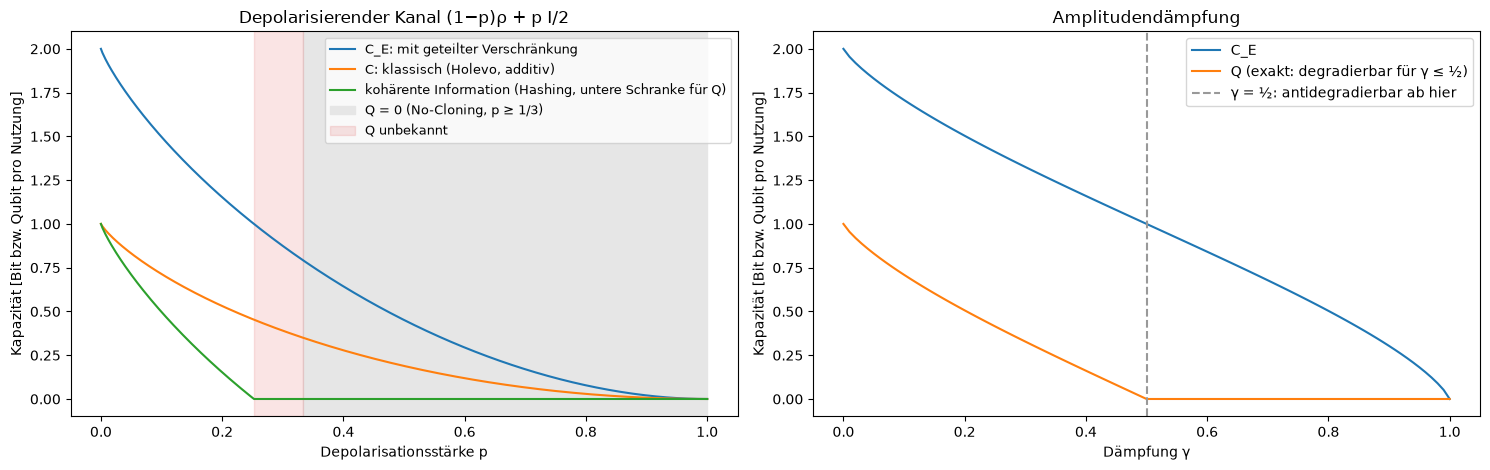

Hashing-Schranke wird null bei p ≈ 0.253; zwischen 0.253 und 1/3 ist Q nicht bekannt.
Bei p = 0.1: C = 0.714, C_E = 1.497, kohärente Information = 0.497
Amplitudendämpfung γ = 0.2: Q = 0.506, C_E = 1.503; γ = 0.6: Q = 0.000


In [12]:
def choi_zustand(K, rho_ein):
    """Gemeinsamer Zustand von Referenz R und Ausgang B, wenn eine Hälfte der Purifikation von rho_ein durch den Kanal geht."""
    w, V = np.linalg.eigh(rho_ein)
    psi = sum(np.sqrt(max(wi, 0)) * np.kron(V[:, i].conj(), V[:, i]) for i, wi in enumerate(w))   # Purifikation auf R ⊗ A
    return sum(np.kron(I2, k) @ dm(psi) @ np.kron(I2, k).conj().T for k in K)


def info_groessen(K, rho_ein):
    rb = choi_zustand(K, rho_ein)
    S_R, S_B, S_RB = entropie(partialspur(rb, [2, 2], [0])), entropie(partialspur(rb, [2, 2], [1])), entropie(rb)
    return S_B - S_RB, S_R + S_B - S_RB                         # kohärente Information, I(R:B)


p_werte = np.linspace(0, 1, 401)
C, Ic, CE = [], [], []
for p in p_werte:
    K = depol(p)
    aus0, aus1 = kanal(K, dm([1, 0])), kanal(K, dm([0, 1]))
    C.append(holevo([aus0, aus1], [0.5, 0.5]))                 # optimal: zwei orthogonale Eingänge (Symmetrie, King 2003)
    ic, ce = info_groessen(K, I2 / 2)
    Ic.append(max(ic, 0)); CE.append(ce)
hashing_null = p_werte[np.argmax(np.array(Ic) <= 1e-9)]

g_werte = np.linspace(0, 1, 101)
Q_ad, CE_ad = [], []
for g in g_werte:
    werte = [info_groessen(ampdaempf(g), np.diag([1 - q, q]).astype(complex)) for q in np.linspace(0, 1, 201)]
    Q_ad.append(max(0, max(v[0] for v in werte))); CE_ad.append(max(v[1] for v in werte))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].plot(p_werte, CE, label="C_E: mit geteilter Verschränkung")
axes[0].plot(p_werte, C, label="C: klassisch (Holevo, additiv)")
axes[0].plot(p_werte, Ic, label="kohärente Information (Hashing, untere Schranke für Q)")
axes[0].axvspan(1 / 3, 1, color="0.9", label="Q = 0 (No-Cloning, p ≥ 1/3)")
axes[0].axvspan(hashing_null, 1 / 3, color="tab:red", alpha=0.12, label="Q unbekannt")
axes[0].set_xlabel("Depolarisationsstärke p"); axes[0].set_ylabel("Kapazität [Bit bzw. Qubit pro Nutzung]")
axes[0].set_title("Depolarisierender Kanal (1−p)ρ + p I/2"); axes[0].legend(fontsize=9)
axes[1].plot(g_werte, CE_ad, label="C_E")
axes[1].plot(g_werte, Q_ad, label="Q (exakt: degradierbar für γ ≤ ½)")
axes[1].axvline(0.5, color="0.6", ls="--", label="γ = ½: antidegradierbar ab hier")
axes[1].set_xlabel("Dämpfung γ"); axes[1].set_ylabel("Kapazität [Bit bzw. Qubit pro Nutzung]")
axes[1].set_title("Amplitudendämpfung"); axes[1].legend()
plt.tight_layout()
plt.show()
print(f"Hashing-Schranke wird null bei p ≈ {hashing_null:.3f}; zwischen {hashing_null:.3f} und 1/3 ist Q nicht bekannt.")
print(f"Bei p = 0.1: C = {np.interp(0.1, p_werte, C):.3f}, C_E = {np.interp(0.1, p_werte, CE):.3f}, "
      f"kohärente Information = {np.interp(0.1, p_werte, Ic):.3f}")
print(f"Amplitudendämpfung γ = 0.2: Q = {Q_ad[20]:.3f}, C_E = {CE_ad[20]:.3f}; γ = 0.6: Q = {Q_ad[60]:.3f}")

#### **Ergebnis**

Beim Lauf vom 2026-10-13:

- **Klassischer Grenzfall:** Für diagonale Zustände sind Spurabstand, Fidelity und relative Entropie auf sechs Stellen gleich TV-Abstand, Bhattacharyya-Fidelity und KL-Divergenz.
- **Qubit:** $T = \tfrac12\vert\vec r - \vec s\vert$ gilt exakt. Für reine Zustände fallen $T$ und $\sqrt{1-F}$ zusammen; für gemischte öffnet sich die Lücke $1 - \sqrt F<T<\sqrt{1-F}$. Der Hilbert-Schmidt-Abstand ist größer als der Spurabstand und hat keine Unterscheidungsbedeutung.
- **Fuchs–van de Graaf und Pinsker:** Alle 3000 zufälligen Paare liegen zwischen den Schranken, reine Paare auf der oberen (Abweichung $2\cdot10^{-15}$). Pinsker gilt für alle Paare (kleinster Abstand zur Schranke 0.0007 Bit).
- **Datenverarbeitung:** Unter 3000 zufälligen Kanälen wachsen Spurabstand, Bures-Abstand und relative Entropie nie (größte Verhältnisse 0.98, 0.97, 0.94). Der Hilbert-Schmidt-Abstand wächst in 0.2 % der Fälle (bis Faktor 1.17) und unter der Partialspur von $\rho\otimes I/d$ genau um $\sqrt d$.
- **Viele Kopien:** $T = 0.29$, $F = 0.915$, Chernoff-Exponent $\xi = 0.048$ bei $s\approx\tfrac12$. Die Blockzerlegung stimmt bis $n = 8$ auf zwölf Stellen mit der direkten Rechnung überein. $-\tfrac1n\ln P_\text{err}$ fällt von 0.18 ($n = 10$) über 0.071 ($n = 100$) auf 0.056 ($n = 400$) und nähert sich $\xi$ von oben, langsam wegen eines Vorfaktors. Der Spurabstand einer Kopie sagt über den Exponenten nichts. Die relativen Entropien (0.195 und 0.196 nat) sind größer als $\xi$: Beim asymmetrischen Testen darf eine Fehlerart konstant bleiben.
- **Entropien:** Die Rényi-Entropien fallen mit $\alpha$ und laufen gegen die Min-Entropie. $S(A\vert B)$ ist für reine Zustände nie positiv (bis $-1$ beim Bell-Zustand) und für Zustände vollen Rangs meist positiv. Starke Subadditivität und Araki–Lieb gelten für alle 3000 zufälligen Zustände dreier Qubits, mit mindestens 0.106 Bit Abstand: Gleichheit braucht spezielle Struktur (Quanten-Markov-Ketten, zum Beispiel Produktzustände).
- **Schumacher:** Die Zählformel stimmt bei $n = 12$ mit der direkten Diagonalisierung überein (0.7811 Qubits pro Kopie). Bei $n = 10^4$ braucht man 0.480 ($\varepsilon = 0.1$) bzw. 0.490 ($\varepsilon = 0.01$) Qubits pro Kopie, gegenüber $S = 0.469$: Die Annäherung von oben ist langsam, etwa wie $1/\sqrt n$.
- **Holevo:** Für zwei reine Zustände ist die Helstrom-Messung die beste projektive Messung und bleibt unter $\chi$. Trine: $\chi = 1$ Bit, Accessible Information 0.585 Bit (numerisch über POVMs mit sechs Elementen gleich dem Anti-Trine), die Trine-Messung selbst nur 0.333 Bit. Tetraeder: $\chi = 1$, Accessible Information 0.415, das SIC-POVM 0.208.
- **Klonen:** Bužek–Hillery gibt jedem Eingang die Fidelity $5/6$, beide Kopien gleich. Die CNOT-Kopie ist nur für $\vert0\rangle$ und $\vert1\rangle$ perfekt, am Äquator 1/2, im Mittel 2/3. No-Signalling: Bobs Zustand ändert sich durch Alices Kanal um $10^{-16}$; sein bedingter Zustand ändert sich nach Alices Messung um $T = 0.27$, das Mittel über ihre Ergebnisse nicht.
- **Quanten-Fisher-Information:** Produkt $N$, GHZ $N^2$ exakt; der Bures-Abstand gibt dieselben Werte auf weniger als 0.1 %. Mit $p = 0.05$ wächst GHZ von 0.81 auf 11.9 bei $N = 8$ und flacht ab (Produkt: 6.5). Nach der Formel $N^2(1-2p)^{2N}$ gegen $N(1-2p)^2$ verliert GHZ ab $N = 14$ gegen den Produktzustand.
- **Kanäle:** Das SDP gibt $\sin(\varepsilon/2)$ und $\tfrac34p$ exakt; ohne Ancilla erreicht man beim depolarisierenden Kanal nur $\tfrac p2$. Bei derselben Fehlerrate $r = 10^{-4}$ ist die Diamantnorm für die Überrotation $1.2\cdot10^{-2}$, für die Depolarisation $1.5\cdot10^{-4}$ und für die Amplitudendämpfung $3.0\cdot10^{-4}$: ein Faktor 80 zwischen kohärent und inkohärent.
- **Kapazitäten:** Depolarisierender Kanal mit $p = 0.1$: $C = 0.714$ Bit, $C_E = 1.497$ Bit, kohärente Information 0.497 Qubit. Die Hashing-Schranke wird bei $p\approx0.253$ null, ab $p = 1/3$ ist $Q = 0$, dazwischen ist $Q$ nicht bekannt. Amplitudendämpfung: $Q = 0.506$ bei $\gamma = 0.2$, $Q = 0$ ab $\gamma = \tfrac12$, während $C_E$ bis $\gamma = 1$ positiv bleibt.

#### **Variationen**

Jeweils zuerst die Vorhersage aufschreiben, dann den Code ändern.

1. **Kommutierende Zustände** (Experiment 4): $\sigma = $ Bloch-Vektor $(0, 0, -0.3)$. Was wird aus dem Chernoff-Exponenten? *(Vorhersage: der klassische Chernoff-Exponent der Eigenwertverteilungen.)*
2. **Größere Systeme** (Experiment 2): Wiederhole Fuchs–van de Graaf für $d = 8$. Rücken die Punkte an eine der Schranken?
3. **Pure-State-Grenze** (Experiment 5): Für reine Zustände ist $S(A\vert B) = -S(B)$. Woran erkennt man das im Histogramm für Rang 1?
4. **Andere Quelle** (Experiment 6): Eigenwerte $0.5, 0.5$. *(Vorhersage: keine Kompression möglich, die Kurve bleibt bei 1.)*
5. **Ungleiche Priors** (Experiment 7): zwei reine Zustände mit $p_0 = 0.9$. Wie ändern sich $\chi$ und die Information der Helstrom-Messung?
6. **Asymmetrische Klonmaschine** (Experiment 8): Eine Kopie mit Fidelity 0.95 – wie gut kann die andere höchstens sein? *(Stichwort: optimale asymmetrische Klonmaschine, $\sqrt{(1-F_1)(1-F_2)}$-Abwägung; erst die Bedingung herleiten.)*
7. **Optimales N bei Dephasierung** (Experiment 9): Für welches $N$ ist $N^2(1-2p)^{2N}$ maximal? *(Vorhersage: $N^* = -1/\ln(1-2p)$, bei $p = 0.05$ etwa 9.5.)*
8. **Kombinierter Fehler** (Experiment 10): Überrotation und Depolarisation mit je halber Fehlerrate. Welche Kurve folgt die Diamantnorm?

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Welche Aufgabe beschreibt der Spurabstand, welche die Fidelity, welche die relative Entropie?</summary>

Spurabstand: beste Unterscheidung mit einer Kopie, $P_\text{succ} = \tfrac12(1 + T)$. Fidelity: größter Überlapp von Purifikationen (Uhlmann). Relative Entropie: Fehlerexponent zweiter Art beim asymmetrischen Testen mit vielen Kopien (Stein).
</details>

<details><summary>2. Wie lauten die Fuchs–van-de-Graaf-Ungleichungen, und wann ist die obere eine Gleichung?</summary>

$1 - \sqrt F\le T\le\sqrt{1 - F}$; Gleichheit rechts für reine Zustände.
</details>

<details><summary>3. Warum ist der Hilbert-Schmidt-Abstand als Fehlermaß problematisch?</summary>

Er ist unter Kanälen nicht monoton: Die Partialspur von $\rho\otimes I/d$ und $\sigma\otimes I/d$ vergrößert ihn um $\sqrt d$. Er hat keine operative Bedeutung als Unterscheidbarkeit.
</details>

<details><summary>4. Was bestimmt, wie schnell der Fehler beim Unterscheiden mit n Kopien fällt?</summary>

Der Quanten-Chernoff-Exponent $\xi = -\ln\min_s\mathrm{Tr}\,\rho^s\sigma^{1-s}$, nicht der Spurabstand einer Kopie.
</details>

<details><summary>5. Was bedeutet negative bedingte Entropie?</summary>

$S(A\vert B)<0$ ist klassisch unmöglich und zeigt Verschränkung an (Bell-Zustand: $-1$). Operativ: Beim State Merging bleibt Verschränkung übrig.
</details>

<details><summary>6. Wie hängt starke Subadditivität mit der Monotonie der relativen Entropie zusammen?</summary>

$I(A{:}BC)\ge I(A{:}B)$ ist die Monotonie von $D(\rho_{ABC}\Vert\rho_A\otimes\rho_{BC})$ unter $\mathrm{Tr}_C$; ausgeschrieben ist das $S(AB) + S(BC)\ge S(ABC) + S(B)$.
</details>

<details><summary>7. Was ist die operative Bedeutung der von-Neumann-Entropie?</summary>

Schumacher: $n$ Kopien von $\rho$ lassen sich in $nS(\rho)$ Qubits speichern, nicht in weniger.
</details>

<details><summary>8. Warum trägt ein Qubit höchstens ein klassisches Bit, und warum ist das bei der Trine weniger?</summary>

Holevo: $I(X{:}Y)\le\chi\le\log d$. Bei der Trine ist $\chi = 1$, aber die beste Messung erreicht nur $\log_23 - 1 = 0.585$ Bit, weil die drei Zustände nicht orthogonal sind.
</details>

<details><summary>9. Was sind C, Q und C_E, und welche ist ohne Grenzwert über viele Nutzungen berechenbar?</summary>

Klassische Kapazität, Quantenkapazität und verschränkungsunterstützte klassische Kapazität. $C_E = \max I(R{:}B)$ ist „single-letter“; $C$ und $Q$ brauchen im Allgemeinen den Grenzwert (Superadditivität).
</details>

<details><summary>10. Welche Fidelity erreicht die beste universelle Klonmaschine, und was folgt daraus für den depolarisierenden Kanal?</summary>

$5/6$, der Bloch-Vektor schrumpft um $2/3$. Jeder depolarisierende Kanal mit Schrumpffaktor $\le2/3$ hat $Q = 0$, sonst könnte man klonen.
</details>

<details><summary>11. Wie hängt die Quanten-Fisher-Information mit dem Bures-Abstand zusammen, und was gibt GHZ?</summary>

$D_B^2 = \tfrac14F_Q\,d\theta^2$; für reine Zustände $F_Q = 4\,\mathrm{Var}(G)$. GHZ: $F_Q = N^2$ (Heisenberg-Limit), Produkt: $N$.
</details>

<details><summary>12. Warum ist eine kohärente Überrotation schlimmer, als ihre mittlere Fidelity vermuten lässt?</summary>

Bei gleicher Fehlerrate $r$ ist ihre Diamantnorm $\sqrt{3r/2}$ statt $3r/2$: Kohärente Fehler addieren sich in Amplituden, inkohärente in Wahrscheinlichkeiten.
</details>

#### **Nächste Schritte**

- **Messungen, die diese Grenzen erreichen:** Helstrom, POVMs, Tomographie, Randomized Benchmarking im Notebook [Quantenmessung](https://github.com/deltorobarba/science/blob/main/quantum/quantummeasurement.ipynb); die projektive Messung im Notebook [Born-Regel](https://github.com/deltorobarba/science/blob/main/quantum/bornrule.ipynb).
- **One-Shot-Informationstheorie:** glatte Min- und Max-Entropien ersetzen $S$, wenn man nur eine Kopie hat (Renner, Tomamichel); Anwendung: Sicherheitsbeweise der Quantenkryptographie.
- **Rényi-Divergenzen:** die gestauchte (sandwiched) Rényi-Divergenz $\tilde D_\alpha$ verbindet relative Entropie ($\alpha\to1$), Max-Divergenz ($\alpha\to\infty$) und Fidelity ($\alpha = \tfrac12$).
- **Verschränkungsmaße:** Verschränkungsentropie, Negativität, Concurrence, Verschränkung der Bildung; Quantum Discord als Korrelation jenseits der Verschränkung.
- **Kapazitäten weiter:** Superadditivität der kohärenten Information, Superaktivierung (zwei Kanäle mit $Q = 0$ zusammen mit $Q>0$), private Kapazität.
- **Metrologie:** die SLD-Messung, die die Cramér–Rao-Schranke erreicht; Grenzen bei Rauschen (Escher, Demkowicz-Dobrzański).

#### **Referenzen**

- M. A. Nielsen, I. L. Chuang: *Quantum Computation and Quantum Information*, Kapitel 9 (Abstandsmaße: 9.2 Spurabstand und Fidelity, 9.3 Kanäle), Kapitel 11 (Entropie: 11.3 von Neumann, 11.4 starke Subadditivität), Kapitel 12 (12.1 Holevo-Schranke und No-Cloning in Box 12.1, 12.2 Schumacher, 12.3 klassische Kapazität).
- J. Watrous: *The Theory of Quantum Information*, Cambridge 2018, Kapitel 3 (Unterscheidbarkeit, Fidelity, Diamantnorm), Kapitel 5 (Entropie), Kapitel 8 (Kapazitäten).
- M. M. Wilde: *Quantum Information Theory*, 2. Aufl., Cambridge 2017, Kapitel 9 (Abstandsmaße), 11 (Entropie), 18 (Schumacher-Kompression), 20 (klassische Kommunikation), 24 (Quantenkommunikation).
- C. A. Fuchs, J. van de Graaf: *Cryptographic distinguishability measures for quantum-mechanical states*, IEEE Trans. Inf. Theory 45, 1216 (1999).
- A. Uhlmann: *The „transition probability“ in the state space of a ∗-algebra*, Rep. Math. Phys. 9, 273 (1976); R. Jozsa: *Fidelity for mixed quantum states*, J. Mod. Opt. 41, 2315 (1994).
- K. M. R. Audenaert et al.: *Discriminating states: the quantum Chernoff bound*, Phys. Rev. Lett. 98, 160501 (2007).
- E. H. Lieb, M. B. Ruskai: *Proof of the strong subadditivity of quantum-mechanical entropy*, J. Math. Phys. 14, 1938 (1973).
- B. Schumacher: *Quantum coding*, Phys. Rev. A 51, 2738 (1995).
- A. S. Holevo: *Bounds for the quantity of information transmitted by a quantum communication channel*, Probl. Inf. Transm. 9, 177 (1973).
- P. W. Shor: *On the number of elements needed in a POVM attaining the accessible information*, arXiv:quant-ph/0009077 (2000).
- C. King: *The capacity of the quantum depolarizing channel*, IEEE Trans. Inf. Theory 49, 221 (2003).
- C. H. Bennett, P. W. Shor, J. A. Smolin, A. V. Thapliyal: *Entanglement-assisted capacity of a quantum channel and the reverse Shannon theorem*, IEEE Trans. Inf. Theory 48, 2637 (2002).
- I. Devetak: *The private classical capacity and quantum capacity of a quantum channel*, IEEE Trans. Inf. Theory 51, 44 (2005).
- W. K. Wootters, W. H. Zurek: *A single quantum cannot be cloned*, Nature 299, 802 (1982); V. Bužek, M. Hillery: *Quantum copying: beyond the no-cloning theorem*, Phys. Rev. A 54, 1844 (1996).
- H. Barnum et al.: *Noncommuting mixed states cannot be broadcast*, Phys. Rev. Lett. 76, 2818 (1996); A. K. Pati, S. L. Braunstein: *Impossibility of deleting an unknown quantum state*, Nature 404, 164 (2000).
- S. L. Braunstein, C. M. Caves: *Statistical distance and the geometry of quantum states*, Phys. Rev. Lett. 72, 3439 (1994).
- J. Watrous: *Semidefinite programs for completely bounded norms*, Theory Comput. 5, 217 (2009).
- M. A. Nielsen: *A simple formula for the average gate fidelity of a quantum dynamical operation*, Phys. Lett. A 303, 249 (2002).
- R. Kueng, D. M. Long, A. C. Doherty, S. T. Flammia: *Comparing experiments to the fault-tolerance threshold*, Phys. Rev. Lett. 117, 170502 (2016).